# 02 — Prévision de la demande — Approche 1 (séries temporelles)

**PFE ENSAI 2025/2026 — Prévision de la demande & Pricing Dynamique**

Cette première approche aborde la prévision de la demande comme un **problème de séries temporelles** au niveau hebdomadaire :

1. **Prophet** — modèle additif avec saisonnalité multiplicative, à l'échelle macro et par établissement.
2. **XGBoost en mode séries temporelles** — comparaison de trois configurations :
   - *Macro* : prévisions globales de la demande hebdomadaire.
   - *2 variables* : ajout de la saisonnalité (semaine ISO).
   - *Multi-variables* : ajout de variables exogènes (PMV, lags, segments).

L'objectif : prévoir le volume de réservations sur une saison touristique (S39 → S38, Oct → Sep).

---


In [116]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import matplotlib.ticker as mticker

import seaborn as sns
from scipy import stats

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

## **IMPORT DE LA BASE**

In [2]:
data = pd.read_csv('Bases_ENSAI_30012026_VACANCES.csv')

In [3]:
data

,CANAL_VENTE,SEGMENT_DOSSIER,CODE_OFFRE,ETABLISSEMENT_NOM,ETABLISSEMENT_TYPE,ETABLISSEMENT_LOCALISATION,ID_ETABLISSEMENT,DUREE_SEJOUR,PARTENAIRE,PARTENAIRE_NIV1_NOM,...,VOLUME_N2FDS,VOLUME_N3DATE,VOLUME_N3FDS,STOCK_N,STOCK_N1DATE,STOCK_N1FDS,STOCK_N2DATE,STOCK_N2FDS,STOCK_N3DATE,STOCK_N3FDS
0,Web,INDIV,NaN,Méribel Mottaret - Le Hameau du Mottaret,Montagne,Tarentaise,78,7n,SKINET TRAVEL,TO ETRANGER,...,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Propriétaire,INDIV,NaN,L'Alpe d'Huez - L'Eclose,Montagne,Dauphiné - Isère,2894,15n+,NaN,NaN,...,0.000000,0.0,0.000000,0.0,0.0,0.0,84.0,84.0,0.0,0.0
2,Web,INDIV,NaN,Carnoux - Shangri-La - Les Hauts de Cassis,Mer,Côte d'Azur,56,7n,BOOKING.COM CV,OTA PASS OTA,...,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,VPC,INDIV,R_EBETE,Châtel - Les Fermes de Chatel,Montagne,Haute Savoie,2326,7n,COULEUR',CE,...,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Propriétaire,INDIV,NaN,Arles - Les Gardians,Campagne,Provence et Luberon,2479,15n+,NaN,NaN,...,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,10.0,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1452167,XFT Web,INDIV,NaN,Cap d'Agde - Nakâra by Odalys,Mer,Languedoc Roussillon,2270,=2,EXPEDIA,OTA PASS OTA,...,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1452168,Web,INDIV,NaN,Arles - Les Gardians,Campagne,Provence et Luberon,2479,=3,CSE CAF DE NICE,CE,...,-0.142857,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1452169,Web,INDIV,NaN,Evian les Bains - Les Chalets d'Evian,Montagne,Haute Savoie,59,=3,GROUPE OBIZ,CE,...,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1452170,VPC,Allotement,R_EBTOE23,Aigues Mortes - Le Mas des Flamants,Mer,Languedoc Roussillon,1844,7n,TUI BELGIUM NV,TO ETRANGER,...,0.000000,0.0,0.142857,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
data.shape

(1452172, 38)

In [5]:
data.columns

Index(['CANAL_VENTE', 'SEGMENT_DOSSIER', 'CODE_OFFRE', 'ETABLISSEMENT_NOM',
       'ETABLISSEMENT_TYPE', 'ETABLISSEMENT_LOCALISATION', 'ID_ETABLISSEMENT',
       'DUREE_SEJOUR', 'PARTENAIRE', 'PARTENAIRE_NIV1_NOM', 'PARTENAIRE_SEG1',
       'PARTENAIRE_SEG2', 'PRESTATION_COMM', 'ID_TYPE_CHAMBRE',
       'SEMAINE_SEJOUR', 'DATE_OBSERVATION', 'ETAT_DOSSIER', 'CA_N',
       'CA_N1DATE', 'CA_N1FDS', 'CA_N2DATE', 'CA_N2FDS', 'CA_N3DATE',
       'CA_N3FDS', 'VOLUME_N', 'VOLUME_N1DATE', 'VOLUME_N1FDS',
       'VOLUME_N2DATE', 'VOLUME_N2FDS', 'VOLUME_N3DATE', 'VOLUME_N3FDS',
       'STOCK_N', 'STOCK_N1DATE', 'STOCK_N1FDS', 'STOCK_N2DATE', 'STOCK_N2FDS',
       'STOCK_N3DATE', 'STOCK_N3FDS'],
      dtype='object')

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1452172 entries, 0 to 1452171
Data columns (total 38 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   CANAL_VENTE                 1452172 non-null  object 
 1   SEGMENT_DOSSIER             1452172 non-null  object 
 2   CODE_OFFRE                  326454 non-null   object 
 3   ETABLISSEMENT_NOM           1452172 non-null  object 
 4   ETABLISSEMENT_TYPE          1452172 non-null  object 
 5   ETABLISSEMENT_LOCALISATION  1452172 non-null  object 
 6   ID_ETABLISSEMENT            1452172 non-null  int64  
 7   DUREE_SEJOUR                1452172 non-null  object 
 8   PARTENAIRE                  1140827 non-null  object 
 9   PARTENAIRE_NIV1_NOM         1140827 non-null  object 
 10  PARTENAIRE_SEG1             1140828 non-null  object 
 11  PARTENAIRE_SEG2             1140563 non-null  object 
 12  PRESTATION_COMM             1452172 non-null  object 
 1

## **NETTOYAGE DE LA BASE**

In [7]:
data.head()

,CANAL_VENTE,SEGMENT_DOSSIER,CODE_OFFRE,ETABLISSEMENT_NOM,ETABLISSEMENT_TYPE,ETABLISSEMENT_LOCALISATION,ID_ETABLISSEMENT,DUREE_SEJOUR,PARTENAIRE,PARTENAIRE_NIV1_NOM,...,VOLUME_N2FDS,VOLUME_N3DATE,VOLUME_N3FDS,STOCK_N,STOCK_N1DATE,STOCK_N1FDS,STOCK_N2DATE,STOCK_N2FDS,STOCK_N3DATE,STOCK_N3FDS
0,Web,INDIV,NaN,Méribel Mottaret - Le Hameau du Mottaret,Montagne,Tarentaise,78,7n,SKINET TRAVEL,TO ETRANGER,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Propriétaire,INDIV,NaN,L'Alpe d'Huez - L'Eclose,Montagne,Dauphiné - Isère,2894,15n+,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,84.0,84.0,0.0,0.0
2,Web,INDIV,NaN,Carnoux - Shangri-La - Les Hauts de Cassis,Mer,Côte d'Azur,56,7n,BOOKING.COM CV,OTA PASS OTA,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,VPC,INDIV,R_EBETE,Châtel - Les Fermes de Chatel,Montagne,Haute Savoie,2326,7n,COULEUR',CE,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Propriétaire,INDIV,NaN,Arles - Les Gardians,Campagne,Provence et Luberon,2479,15n+,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,10.0


In [8]:
# TRANSFORMER EN CATEGORY
category_list = ['CANAL_VENTE', 'SEGMENT_DOSSIER', 'CODE_OFFRE', 'ETABLISSEMENT_TYPE', 'ETABLISSEMENT_LOCALISATION', 'DUREE_SEJOUR',
               'PARTENAIRE', 'PARTENAIRE_NIV1_NOM', 'PARTENAIRE_SEG1', 'PARTENAIRE_SEG2', 'ETAT_DOSSIER']

data[category_list] = data[category_list].astype('category')

In [9]:
# VARIABLE CODE PROMO
data['PROMO'] = data['CODE_OFFRE'].notna()

In [10]:
# TRANSFORMER EN STR
str_list = ['ID_ETABLISSEMENT', 'ID_TYPE_CHAMBRE']

data[str_list] = data[str_list].astype(str)

In [11]:
## CREATION D'UNE NOUVELLE VARIABLE VILLE
data['VILLE'] = data['ETABLISSEMENT_NOM'].str.split(' - ').str[0]
data['VILLE'].sample(10)

28889                  Hourtin
267975           L'Alpe d'Huez
505881                   Arles
292544           Aigues Mortes
876605              Le Paradou
983880                Bergheim
619937                 Erdeven
862543              Valmeinier
577536              Font Romeu
773778    Les Carroz d'Arâches
Name: VILLE, dtype: object

In [12]:
## TRAITEMENT NA PARTENAIRE
partenaire = ['PARTENAIRE', 'PARTENAIRE_NIV1_NOM', 'PARTENAIRE_SEG1', 'PARTENAIRE_SEG2']

for i in partenaire:
    data[i] = data[i].cat.add_categories("PARTENAIRE INCONNU").fillna("PARTENAIRE INCONNU")

In [13]:
## NOUVELLE VARIABLE QUI CAPTURE LE NOMBRE DE PERSONNES DANS UNE CHAMBRE A PARTIR DE PRESTATION_COMM
data['NB_PERS_CHAMBRE'] = data['PRESTATION_COMM'].str.extract(r'(\d+)(?:/\d+)?\s*pers\.').astype('Int64')

In [14]:
data['DATE_OBSERVATION'] = pd.to_datetime(data['DATE_OBSERVATION'])
data['YEAR_OBS'] = data['DATE_OBSERVATION'].dt.year

In [15]:
data['DIFF_JOURS_SEJOUR'] = (pd.to_datetime(data['SEMAINE_SEJOUR']) - pd.to_datetime(data['DATE_OBSERVATION'])).dt.days

In [16]:
# CREATION DE LA VARIABLE SAISON_SEJOUR
# Hiver : Octobre à Mars / Ete : Avril à Septembre
mois = pd.to_datetime(data['SEMAINE_SEJOUR']).dt.month
data['SAISON_SEJOUR'] = np.where(mois.isin([10, 11, 12, 1, 2, 3]), 'Hiver', 'Ete')
data['SAISON_SEJOUR'] = data['SAISON_SEJOUR'].astype('category')

In [17]:
data['PRIX_MOYEN_N'] = data['CA_N'] / data['VOLUME_N']
data['PRIX_MOYEN_N1'] = data['CA_N1FDS'] / data['VOLUME_N1FDS']
data['PRIX_MOYEN_N2'] = data['CA_N2FDS'] / data['VOLUME_N2FDS']
data['PRIX_MOYEN_N3'] = data['CA_N3FDS'] / data['VOLUME_N3FDS']

In [18]:
data.head(5)

,CANAL_VENTE,SEGMENT_DOSSIER,CODE_OFFRE,ETABLISSEMENT_NOM,ETABLISSEMENT_TYPE,ETABLISSEMENT_LOCALISATION,ID_ETABLISSEMENT,DUREE_SEJOUR,PARTENAIRE,PARTENAIRE_NIV1_NOM,...,PROMO,VILLE,NB_PERS_CHAMBRE,YEAR_OBS,DIFF_JOURS_SEJOUR,SAISON_SEJOUR,PRIX_MOYEN_N,PRIX_MOYEN_N1,PRIX_MOYEN_N2,PRIX_MOYEN_N3
0,Web,INDIV,NaN,Méribel Mottaret - Le Hameau du Mottaret,Montagne,Tarentaise,78,7n,SKINET TRAVEL,TO ETRANGER,...,False,Méribel Mottaret,6,2025,61,Hiver,1047.201047,NaN,NaN,NaN
1,Propriétaire,INDIV,NaN,L'Alpe d'Huez - L'Eclose,Montagne,Dauphiné - Isère,2894,15n+,PARTENAIRE INCONNU,PARTENAIRE INCONNU,...,False,L'Alpe d'Huez,6,2024,614,Ete,NaN,NaN,NaN,NaN
2,Web,INDIV,NaN,Carnoux - Shangri-La - Les Hauts de Cassis,Mer,Côte d'Azur,56,7n,BOOKING.COM CV,OTA PASS OTA,...,False,Carnoux,5,2025,89,Hiver,191.149191,NaN,NaN,NaN
3,VPC,INDIV,R_EBETE,Châtel - Les Fermes de Chatel,Montagne,Haute Savoie,2326,7n,COULEUR',CE,...,True,Châtel,6,2025,222,Ete,1250.101250,NaN,NaN,NaN
4,Propriétaire,INDIV,NaN,Arles - Les Gardians,Campagne,Provence et Luberon,2479,15n+,PARTENAIRE INCONNU,PARTENAIRE INCONNU,...,False,Arles,4,2022,1202,Hiver,NaN,NaN,NaN,NaN


In [19]:
## GESTION DES DONNEES DE STOCK
data_stocks = data[data['ETAT_DOSSIER'].isna()]
to_drop = data_stocks.columns[data_stocks.columns.str.contains("CA|VOLUME", regex=True)]
data_stocks = data_stocks.drop(columns=to_drop)

cols_stock = ['STOCK_N', 'STOCK_N1FDS', 'STOCK_N1DATE','STOCK_N2FDS', 'STOCK_N3FDS']
stock = (
    data_stocks
    .groupby('ID_TYPE_CHAMBRE', as_index=False)[cols_stock]
    .max()
)

stock

data = data.merge(
    stock[['ID_TYPE_CHAMBRE', 'STOCK_N']].rename(columns={'STOCK_N': 'STOCK'}),
    on='ID_TYPE_CHAMBRE',
    how='left'
)


In [20]:
cols_to_drop = [
    'STOCK_N', 
    'STOCK_N1DATE', 'STOCK_N1FDS',
    'STOCK_N2DATE', 'STOCK_N2FDS',
    'STOCK_N3DATE', 'STOCK_N3FDS'
]

data = data.drop(columns=cols_to_drop)

data = data[data['ETAT_DOSSIER'].notna()]

In [21]:
data.head()

,CANAL_VENTE,SEGMENT_DOSSIER,CODE_OFFRE,ETABLISSEMENT_NOM,ETABLISSEMENT_TYPE,ETABLISSEMENT_LOCALISATION,ID_ETABLISSEMENT,DUREE_SEJOUR,PARTENAIRE,PARTENAIRE_NIV1_NOM,...,VILLE,NB_PERS_CHAMBRE,YEAR_OBS,DIFF_JOURS_SEJOUR,SAISON_SEJOUR,PRIX_MOYEN_N,PRIX_MOYEN_N1,PRIX_MOYEN_N2,PRIX_MOYEN_N3,STOCK
0,Web,INDIV,NaN,Méribel Mottaret - Le Hameau du Mottaret,Montagne,Tarentaise,78,7n,SKINET TRAVEL,TO ETRANGER,...,Méribel Mottaret,6,2025,61,Hiver,1047.201047,NaN,NaN,NaN,6.0
2,Web,INDIV,NaN,Carnoux - Shangri-La - Les Hauts de Cassis,Mer,Côte d'Azur,56,7n,BOOKING.COM CV,OTA PASS OTA,...,Carnoux,5,2025,89,Hiver,191.149191,NaN,NaN,NaN,53.0
3,VPC,INDIV,R_EBETE,Châtel - Les Fermes de Chatel,Montagne,Haute Savoie,2326,7n,COULEUR',CE,...,Châtel,6,2025,222,Ete,1250.101250,NaN,NaN,NaN,23.0
5,Propriétaire,INDIV,NaN,Les Arcs - Eden by Odalys,Montagne,Tarentaise,2351,7n,PROPRIETAIRE,PROPRIETAIRE,...,Les Arcs,6,2025,173,Hiver,-inf,-0.0,NaN,NaN,28.0
6,VPC,INDIV,R_EBH26,Valloire - Le Hameau et les Chalets de la Vall...,Montagne,Maurienne,142,7n,ODALYS ( INDIV ),ODALYS ( INDIV ),...,Valloire,4,2025,159,Hiver,1949.001949,NaN,NaN,NaN,16.0


In [22]:
# Volumes N-1 EOS par type de destination
n1_by_dest = (
    data
    .groupby('ETABLISSEMENT_TYPE')['VOLUME_N1FDS']
    .sum()
    .reset_index()
    .rename(columns={'VOLUME_N1FDS': 'N1_EOS'})
    .sort_values('N1_EOS', ascending=False)
)
n1_by_dest['SHARE'] = n1_by_dest['N1_EOS'] / n1_by_dest['N1_EOS'].sum() * 100
print(n1_by_dest)
print(f"\nTotal N-1 EOS : {n1_by_dest['N1_EOS'].sum():,.0f}")

# Et pour contrôle : volumes N-1 EOS par segment
n1_by_seg = (
    data
    .groupby('PARTENAIRE_SEG2')['VOLUME_N1FDS']
    .sum()
    .reset_index()
    .rename(columns={'VOLUME_N1FDS': 'N1_EOS'})
    .sort_values('N1_EOS', ascending=False)
)
print("\n", n1_by_seg)
print(f"\nTotal N-1 EOS : {n1_by_seg['N1_EOS'].sum():,.0f}")

  ETABLISSEMENT_TYPE        N1_EOS      SHARE
1                Mer  90729.493584  51.486175
2           Montagne  62561.996921  35.501994
0           Campagne  22929.590785  13.011832

Total N-1 EOS : 176,221

          PARTENAIRE_SEG2        N1_EOS
16              Part CSE  27933.602739
2                Booking  26755.997204
26                   Web  14994.293254
21           TO Etranger  14276.569040
22           TO Français  11497.593395
7           CSE Linéaire  10195.423156
8            CSE Request  10125.155879
24                   VSP   8774.714260
3                   CGOS   8299.862041
25  Vente Evenementielle   7181.572467
5         CSE Allotement   6489.288216
13     Groupe/Séminaires   6039.427726
4                   CNAS   4227.146385
14        Macif Services   4199.575630
9            Call Center   4080.145264
18          Propriétaire   3457.145247
12               Expedia   2378.999546
11                 Ekoya   1282.001055
0                Agences    996.714639
1        

C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1904226371.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('ETABLISSEMENT_TYPE')['VOLUME_N1FDS']
C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1904226371.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('PARTENAIRE_SEG2')['VOLUME_N1FDS']


In [23]:
# ── TABLE 1 : Volumes at date (cross-season comparison) ──────────────────────

saison = data['SAISON_SEJOUR']  # 'Ete' / 'Hiver'

at_date = pd.DataFrame({
    'Period'  : ['N (current)', 'N-1 at date', 'N-2 at date', 'N-3 at date'],
    'Total'   : [
        data['VOLUME_N'].sum(),
        data['VOLUME_N1DATE'].sum(),
        data['VOLUME_N2DATE'].sum(),
        data['VOLUME_N3DATE'].sum(),
    ],
    'Summer'  : [
        data.loc[saison == 'Ete', 'VOLUME_N'].sum(),
        data.loc[saison == 'Ete', 'VOLUME_N1DATE'].sum(),
        data.loc[saison == 'Ete', 'VOLUME_N2DATE'].sum(),
        data.loc[saison == 'Ete', 'VOLUME_N3DATE'].sum(),
    ],
    'Winter'  : [
        data.loc[saison == 'Hiver', 'VOLUME_N'].sum(),
        data.loc[saison == 'Hiver', 'VOLUME_N1DATE'].sum(),
        data.loc[saison == 'Hiver', 'VOLUME_N2DATE'].sum(),
        data.loc[saison == 'Hiver', 'VOLUME_N3DATE'].sum(),
    ],
})
at_date = at_date.set_index('Period')
print("=== TABLE 1 — Volumes at date ===")
print(at_date.applymap(lambda x: f"{x:,.0f}"))

# ── TABLE 2 : End-of-season volumes (EOS) ────────────────────────────────────

eos = pd.DataFrame({
    'Period'  : ['N-1 EOS', 'N-2 EOS', 'N-3 EOS'],
    'Total'   : [
        data['VOLUME_N1FDS'].sum(),
        data['VOLUME_N2FDS'].sum(),
        data['VOLUME_N3FDS'].sum(),
    ],
    'Summer'  : [
        data.loc[saison == 'Ete', 'VOLUME_N1FDS'].sum(),
        data.loc[saison == 'Ete', 'VOLUME_N2FDS'].sum(),
        data.loc[saison == 'Ete', 'VOLUME_N3FDS'].sum(),
    ],
    'Winter'  : [
        data.loc[saison == 'Hiver', 'VOLUME_N1FDS'].sum(),
        data.loc[saison == 'Hiver', 'VOLUME_N2FDS'].sum(),
        data.loc[saison == 'Hiver', 'VOLUME_N3FDS'].sum(),
    ],
})
eos = eos.set_index('Period')
print("\n=== TABLE 2 — End-of-season (EOS) ===")
print(eos.applymap(lambda x: f"{x:,.0f}"))

=== TABLE 1 — Volumes at date ===
              Total  Summer  Winter
Period                             
N (current)  99,204  31,010  68,194
N-1 at date  96,786  30,811  65,975
N-2 at date  90,181  27,901  62,280
N-3 at date  86,150  26,826  59,324

=== TABLE 2 — End-of-season (EOS) ===
           Total   Summer  Winter
Period                           
N-1 EOS  176,221  104,936  71,285
N-2 EOS  162,092   95,399  66,693
N-3 EOS  159,401   95,342  64,059


C:\Users\HP\AppData\Local\Temp\ipykernel_19476\3626515698.py:28: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  print(at_date.applymap(lambda x: f"{x:,.0f}"))
C:\Users\HP\AppData\Local\Temp\ipykernel_19476\3626515698.py:52: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  print(eos.applymap(lambda x: f"{x:,.0f}"))


In [24]:
# STOCK RESTANT
# Nombre d’unités encore disponibles à la vente.

data["STOCK_RESTANT_N"] = data["STOCK"] - data["VOLUME_N"]
data["STOCK_RESTANT_N1"] = data["STOCK"] - data["VOLUME_N1FDS"]
data["STOCK_RESTANT_N2"] = data["STOCK"] - data["VOLUME_N2FDS"]
data["STOCK_RESTANT_N3"] = data["STOCK"] - data["VOLUME_N3FDS"]

In [25]:
## TAUX D'OCCUPATION
# Proportion du stock total déjà vendu pour une date de séjour donnée

data["TAUX_OCCUPATION_N"] =  data["VOLUME_N"] / data["STOCK"]
data["TAUX_OCCUPATION_N1"] = data["VOLUME_N1FDS"] / data["STOCK"]
data["TAUX_OCCUPATION_N2"] = data["VOLUME_N2FDS"] / data["STOCK"]
data["TAUX_OCCUPATION_N3"] = data["VOLUME_N3FDS"] / data["STOCK"]


In [26]:
## BOOKING PACE
# Variation du volume de réservations entre deux observations successives pour une même date de séjour



## **PREPARATION DE LA BASE TEMPORELLE**

In [27]:
data_temp = (
    data
    .groupby(['SEMAINE_SEJOUR'])
    .agg(
        CA_N=('CA_N', 'sum'),
        VOLUME_N=('VOLUME_N', 'sum'),
        CA_N1=('CA_N1FDS', 'sum'),
        VOLUME_N1=('VOLUME_N1FDS', 'sum'),
        CA_N2=('CA_N2FDS', 'sum'),
        VOLUME_N2=('VOLUME_N2FDS', 'sum'),
        CA_N3=('CA_N3FDS', 'sum'),
        VOLUME_N3=('VOLUME_N3FDS', 'sum'),
    )
    .reset_index()
)

data_temp['SEMAINE_SEJOUR'] = pd.to_datetime(data_temp['SEMAINE_SEJOUR'])
data_temp = data_temp.sort_values(['SEMAINE_SEJOUR']).reset_index(drop=True)


data_temp['CA_MOYEN_N'] = data_temp['CA_N'] / data_temp['VOLUME_N']

data_temp['SEMAINE'] = (
    'S' + data_temp['SEMAINE_SEJOUR'].dt.isocalendar().week.astype(str)
    + '-' + data_temp['SEMAINE_SEJOUR'].dt.year.astype(str)
)

In [28]:
data_temp.head()

,SEMAINE_SEJOUR,CA_N,VOLUME_N,CA_N1,VOLUME_N1,CA_N2,VOLUME_N2,CA_N3,VOLUME_N3,CA_MOYEN_N,SEMAINE
0,2025-09-27,4.125656e+05,1146.144028,4.226848e+05,1200.143958,3.673736e+05,1121.001373,2.933150e+05,949.572776,359.959651,S39-2025
1,2025-10-04,7.788440e+05,2271.430718,7.073838e+05,2106.287403,6.794705e+05,2037.859335,5.315237e+05,1780.859429,342.886975,S40-2025
2,2025-10-11,6.850175e+05,2001.429654,5.607589e+05,1715.143717,4.705585e+05,1396.858614,4.247091e+05,1382.144203,342.264111,S41-2025
3,2025-10-18,1.212712e+06,2954.285980,1.237725e+06,3153.142682,1.116447e+06,2905.857498,1.001991e+06,2709.571106,410.492396,S42-2025
4,2025-10-25,1.091490e+06,2655.285666,1.158166e+06,2997.712957,1.094845e+06,2838.856948,1.085416e+06,2767.999124,411.063157,S43-2025


In [29]:
%pip install isoweek

Note: you may need to restart the kernel to use updated packages.


In [30]:
from isoweek import Week
import pandas as pd

data_temp['WEEK_ISO'] = data_temp['SEMAINE_SEJOUR'].dt.isocalendar().week.astype(int)
data_temp['YEAR_N'] = data_temp['SEMAINE_SEJOUR'].dt.isocalendar().year.astype(int)

frames = []

# Année N : on garde les vraies dates
df_n = data_temp[['SEMAINE_SEJOUR', 'WEEK_ISO', 'VOLUME_N', 'CA_N']].copy()
df_n.columns = ['DATE', 'WEEK_ISO', 'VOLUME', 'CA']
df_n['ANNEE'] = 'N'
frames.append(df_n)

# Années N-1, N-2, N-3 : on reconstruit les vraies dates via isoweek
for i, label in enumerate(['N1', 'N2', 'N3'], start=1):
    vol_col = f'VOLUME_{label}'
    ca_col = f'CA_{label}'
    
    df = data_temp[['WEEK_ISO', 'YEAR_N', vol_col, ca_col]].copy()
    df.columns = ['WEEK_ISO', 'YEAR_N', 'VOLUME', 'CA']
    df['ANNEE'] = f'N-{i}'
    
    # Vraie date : même semaine ISO mais année N-i
    df['DATE'] = df.apply(
        lambda row: Week(row['YEAR_N'] - i, row['WEEK_ISO']).saturday(), axis=1
    )
    df['DATE'] = pd.to_datetime(df['DATE'])
    
    frames.append(df[['DATE', 'WEEK_ISO', 'VOLUME', 'CA', 'ANNEE']])

serie_continue = pd.concat(frames).sort_values('DATE').reset_index(drop=True)

# Vérification
print(serie_continue.groupby('ANNEE')['VOLUME'].sum())
print(serie_continue['DATE'].duplicated().sum())
print(len(serie_continue))

ANNEE
N       99203.833073
N-1    176221.081291
N-2    162091.671087
N-3    159401.240978
Name: VOLUME, dtype: float64
3
212


In [31]:
serie_continue = (
    serie_continue
    .sort_values('DATE')
    .drop_duplicates(subset='DATE', keep='first')
    .reset_index(drop=True)
)

print(serie_continue['DATE'].duplicated().sum())
print(len(serie_continue))
print(serie_continue.groupby('ANNEE')['VOLUME'].sum())

0
209
ANNEE
N       98057.689045
N-1    176221.081291
N-2    160204.669183
N-3    157511.953005
Name: VOLUME, dtype: float64


In [32]:
serie = serie_continue
serie.head()
 

,DATE,WEEK_ISO,VOLUME,CA,ANNEE
0,2022-10-01,39,949.572776,2.933150e+05,N-3
1,2022-10-08,40,1780.859429,5.315237e+05,N-3
2,2022-10-15,41,1382.144203,4.247091e+05,N-3
3,2022-10-22,42,2709.571106,1.001991e+06,N-3
4,2022-10-29,43,2767.999124,1.085416e+06,N-3


## **ANALYSE TEMPORELLE DU CA**

Les données sont disponibles à la granularité hebdomadaire, la semaine commençant le samedi selon le référentiel ISO. L'année fiscale s'étend de la semaine 39 (fin septembre) à la semaine 38 (début septembre de l'année suivante), ce qui correspond aux deux saisons métier hiver (octobre–mars) et été (avril–septembre).

L'historique couvre l'année en cours (N) ainsi que trois années comparatives (N-1, N-2, N-3), disponibles sous forme de colonnes _N1DATE, _N2DATE, _N3DATE. Ces colonnes représentent les volumes observés pour la même semaine ISO lors des années précédentes — il s'agit donc d'une structure comparative et non d'une vraie série temporelle continue.

Pour construire une série exploitable par un modèle de forecasting, les vraies dates historiques ont été reconstruites à partir du numéro de semaine ISO et de l'année réelle, en utilisant la librairie isoweek. La série finale couvre 4 saisons pour 104 établissements, soit environ 21 000 observations.

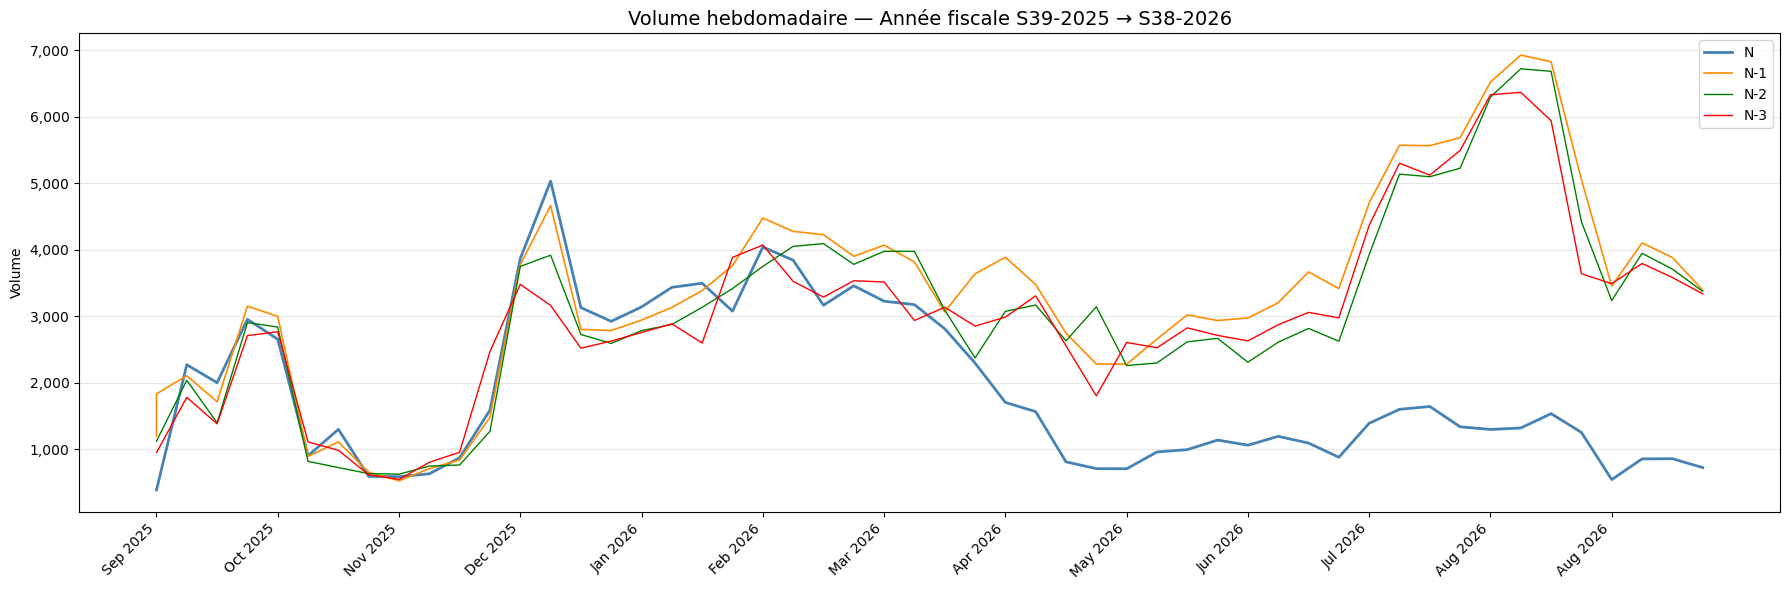

In [33]:
# Réordonner les semaines : S39 à S52, puis S1 à S38
semaines_ordre = list(range(39, 53)) + list(range(1, 39))
semaine_to_pos = {s: i+1 for i, s in enumerate(semaines_ordre)}

serie['POSITION'] = serie['WEEK_ISO'].map(semaine_to_pos)

# Labels mois approximatifs sur l'axe (basé sur l'année N)
mois_labels = (
    data_temp[['WEEK_ISO', 'SEMAINE_SEJOUR']]
    .drop_duplicates('WEEK_ISO')
    .assign(POSITION=lambda x: x['WEEK_ISO'].map(semaine_to_pos))
    .assign(MOIS=lambda x: x['SEMAINE_SEJOUR'].dt.strftime('%b %Y'))
    .sort_values('POSITION')
)

# Tick tous les 4-5 semaines pour ne pas surcharger
tick_positions = mois_labels.iloc[::4]['POSITION'].tolist()
tick_labels = mois_labels.iloc[::4]['MOIS'].tolist()

# Plot
fig, ax = plt.subplots(figsize=(18, 6))

colors = {'N': 'steelblue', 'N-1': 'darkorange', 'N-2': 'green', 'N-3': 'red'}
linewidths = {'N': 2, 'N-1': 1.2, 'N-2': 1, 'N-3': 1}

for annee, group in serie.groupby('ANNEE'):
    group_sorted = group.sort_values('POSITION')
    ax.plot(group_sorted['POSITION'], group_sorted['VOLUME'],
            label=annee, color=colors[annee], linewidth=linewidths[annee])

ax.set_title('Volume hebdomadaire — Année fiscale S39-2025 → S38-2026', fontsize=14)
ax.set_xlabel('')
ax.set_ylabel('Volume')
ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=45, ha='right')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

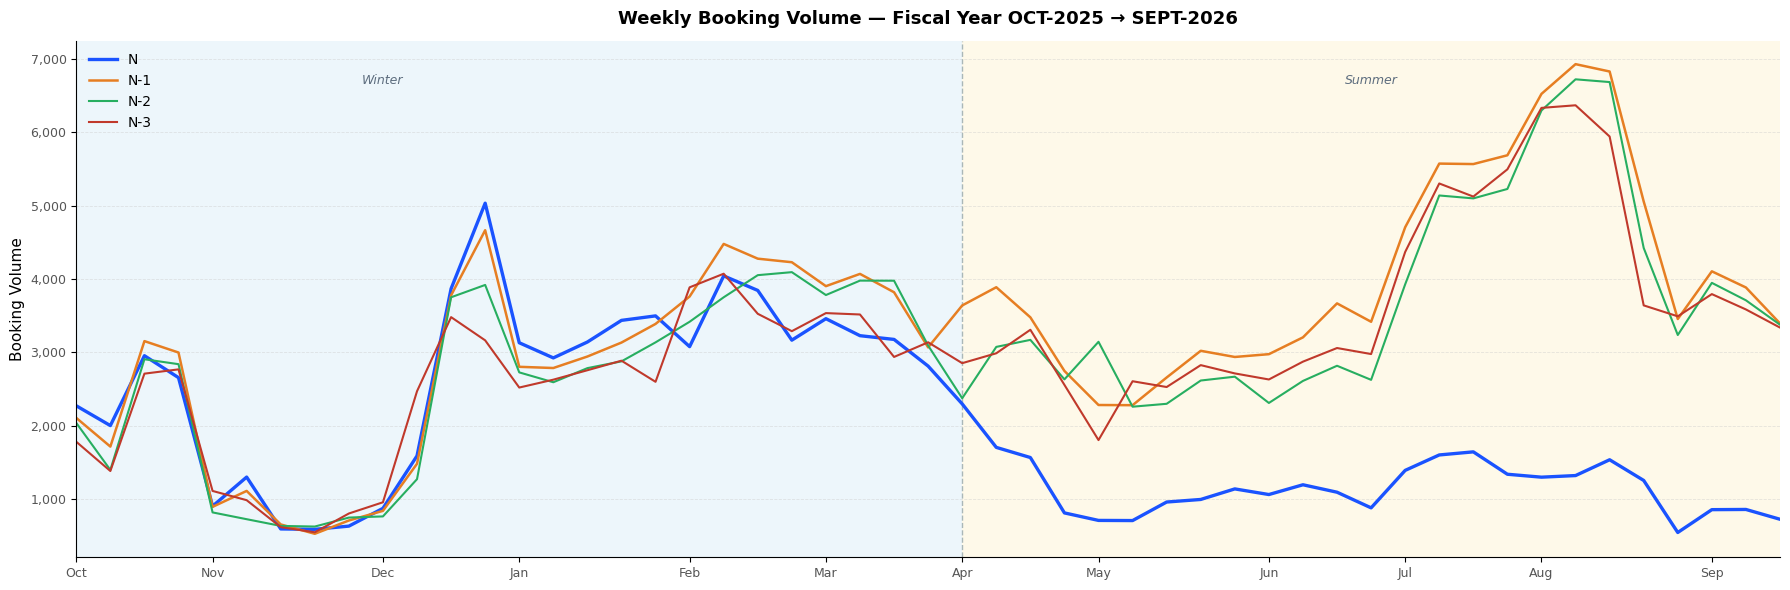

In [34]:
from isoweek import Week
import matplotlib.ticker as mticker

# ── Construction data_temp ────────────────────────────────────────────────────
data['SEMAINE_SEJOUR'] = pd.to_datetime(data['SEMAINE_SEJOUR'])

data_temp = (
    data
    .groupby('SEMAINE_SEJOUR')
    .agg(
        VOLUME_N  = ('VOLUME_N',    'sum'),
        VOLUME_N1 = ('VOLUME_N1FDS','sum'),
        VOLUME_N2 = ('VOLUME_N2FDS','sum'),
        VOLUME_N3 = ('VOLUME_N3FDS','sum'),
    )
    .reset_index()
    .sort_values('SEMAINE_SEJOUR')
    .reset_index(drop=True)
)
data_temp['WEEK_ISO'] = data_temp['SEMAINE_SEJOUR'].dt.isocalendar().week.astype(int)
data_temp['YEAR_N']   = data_temp['SEMAINE_SEJOUR'].dt.isocalendar().year.astype(int)

# ── Construction serie ────────────────────────────────────────────────────────
frames = []

df_n = data_temp[['SEMAINE_SEJOUR','WEEK_ISO','VOLUME_N']].copy()
df_n.columns = ['DATE','WEEK_ISO','VOLUME']
df_n['ANNEE'] = 'N'
frames.append(df_n)

for i, label in enumerate(['N1','N2','N3'], start=1):
    df = data_temp[['WEEK_ISO','YEAR_N', f'VOLUME_{label}']].copy()
    df.columns = ['WEEK_ISO','YEAR_N','VOLUME']
    df['DATE'] = df.apply(
        lambda r: Week(int(r['YEAR_N']) - i, int(r['WEEK_ISO'])).monday(), axis=1
    )
    df['DATE']  = pd.to_datetime(df['DATE'])
    df['ANNEE'] = f'N-{i}'
    frames.append(df[['DATE','WEEK_ISO','VOLUME','ANNEE']])

serie = (
    pd.concat(frames)
    .sort_values('DATE')
    .drop_duplicates(subset=['DATE','ANNEE'], keep='first')
    .reset_index(drop=True)
)

# ── Mapping positions : S40 → S38 ────────────────────────────────────────────
semaines_ordre = list(range(40, 53)) + list(range(1, 39))
semaine_to_pos = {s: i + 1 for i, s in enumerate(semaines_ordre)}

serie['POSITION'] = serie['WEEK_ISO'].map(semaine_to_pos)

# ── Ticks mensuels : 1er tick par mois, centré sur la 1ère semaine du mois ───
tick_df = (
    data_temp[['WEEK_ISO','SEMAINE_SEJOUR']]
    .drop_duplicates('WEEK_ISO')
    .assign(POSITION = lambda x: x['WEEK_ISO'].map(semaine_to_pos))
    .assign(MOIS_NUM  = lambda x: x['SEMAINE_SEJOUR'].dt.month)
    .assign(MOIS_LABEL= lambda x: x['SEMAINE_SEJOUR'].dt.strftime('%b'))
    .dropna(subset=['POSITION'])
    .sort_values('POSITION')
    .drop_duplicates('MOIS_NUM', keep='first')   # première semaine de chaque mois
)
tick_positions = tick_df['POSITION'].tolist()
tick_labels    = tick_df['MOIS_LABEL'].tolist()

# ── Frontières saisonnières ───────────────────────────────────────────────────
pos_winter_end   = semaine_to_pos[14]                          # S14 = début avril
pos_summer_end   = semaine_to_pos[38]                          # S38 = fin été
pos_winter_label = semaine_to_pos[49]                          # décembre
pos_summer_label = (pos_winter_end + pos_summer_end) // 2     # juillet

# ── Plot ──────────────────────────────────────────────────────────────────────
plt.rcParams.update({'font.family': 'sans-serif',
                     'axes.spines.top': False, 'axes.spines.right': False})

fig, ax = plt.subplots(figsize=(18, 6))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

ax.axvspan(1,              pos_winter_end, color='#EBF5FB', alpha=0.9, lw=0, zorder=0)
ax.axvspan(pos_winter_end, pos_summer_end, color='#FEF9E7', alpha=0.9, lw=0, zorder=0)
ax.axvline(pos_winter_end, color='#AAB7B8', linewidth=1, linestyle='--', zorder=1)

ymax = serie['VOLUME'].max()
ax.text(pos_winter_label, ymax * 0.96, 'Winter',
        fontsize=9, color='#5D6D7E', fontstyle='italic', ha='center')
ax.text(pos_summer_label, ymax * 0.96, 'Summer',
        fontsize=9, color='#5D6D7E', fontstyle='italic', ha='center')

colors     = {'N': '#1A53FF', 'N-1': '#E67E22', 'N-2': '#27AE60', 'N-3': '#C0392B'}
linewidths = {'N': 2.4, 'N-1': 1.8, 'N-2': 1.5, 'N-3': 1.5}

for annee, group in serie.groupby('ANNEE'):
    g = group.sort_values('POSITION')
    ax.plot(g['POSITION'], g['VOLUME'],
            label=annee, color=colors.get(annee, 'gray'),
            linewidth=linewidths.get(annee, 1.5), zorder=2)

ax.set_title('Weekly Booking Volume — Fiscal Year OCT-2025 → SEPT-2026',
             fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Booking Volume', fontsize=11)
ax.set_xlabel('')
ax.set_xlim(1, pos_summer_end)
ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=0, ha='center', fontsize=9, color='#555555')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.tick_params(axis='y', labelsize=9, labelcolor='#555555')
ax.grid(axis='y', linestyle='--', linewidth=0.6, alpha=0.5, color='#CCCCCC')
ax.set_axisbelow(True)
ax.legend(fontsize=10, frameon=False, loc='upper left')

plt.tight_layout()
plt.show()


### **PROPHET**

In [35]:
df_prophet = serie_continue[['DATE', 'VOLUME']].copy()
df_prophet.columns = ['ds', 'y']

# Vérifications
print(df_prophet.dtypes)
print(df_prophet.isnull().sum())
print(df_prophet.head())
print(df_prophet.tail())

ds    datetime64[ns]
y            float64
dtype: object
ds    0
y     0
dtype: int64
          ds            y
0 2022-10-01   949.572776
1 2022-10-08  1780.859429
2 2022-10-15  1382.144203
3 2022-10-22  2709.571106
4 2022-10-29  2767.999124
            ds           y
204 2026-08-29  544.000528
205 2026-09-05  855.286858
206 2026-09-12  858.001006
207 2026-09-19  724.286522
208 2026-09-26  387.000213


In [36]:
%pip install prophet

Note: you may need to restart the kernel to use updated packages.


In [37]:
from prophet import Prophet

model = Prophet(
    seasonality_mode='multiplicative',  # car les pics s'amplifient avec le niveau
    yearly_seasonality=True,
    weekly_seasonality=False,           # on est déjà en hebdomadaire
    daily_seasonality=False,
)

model.fit(df_prophet)

23:19:29 - cmdstanpy - INFO - Chain [1] start processing
23:19:30 - cmdstanpy - INFO - Chain [1] done processing


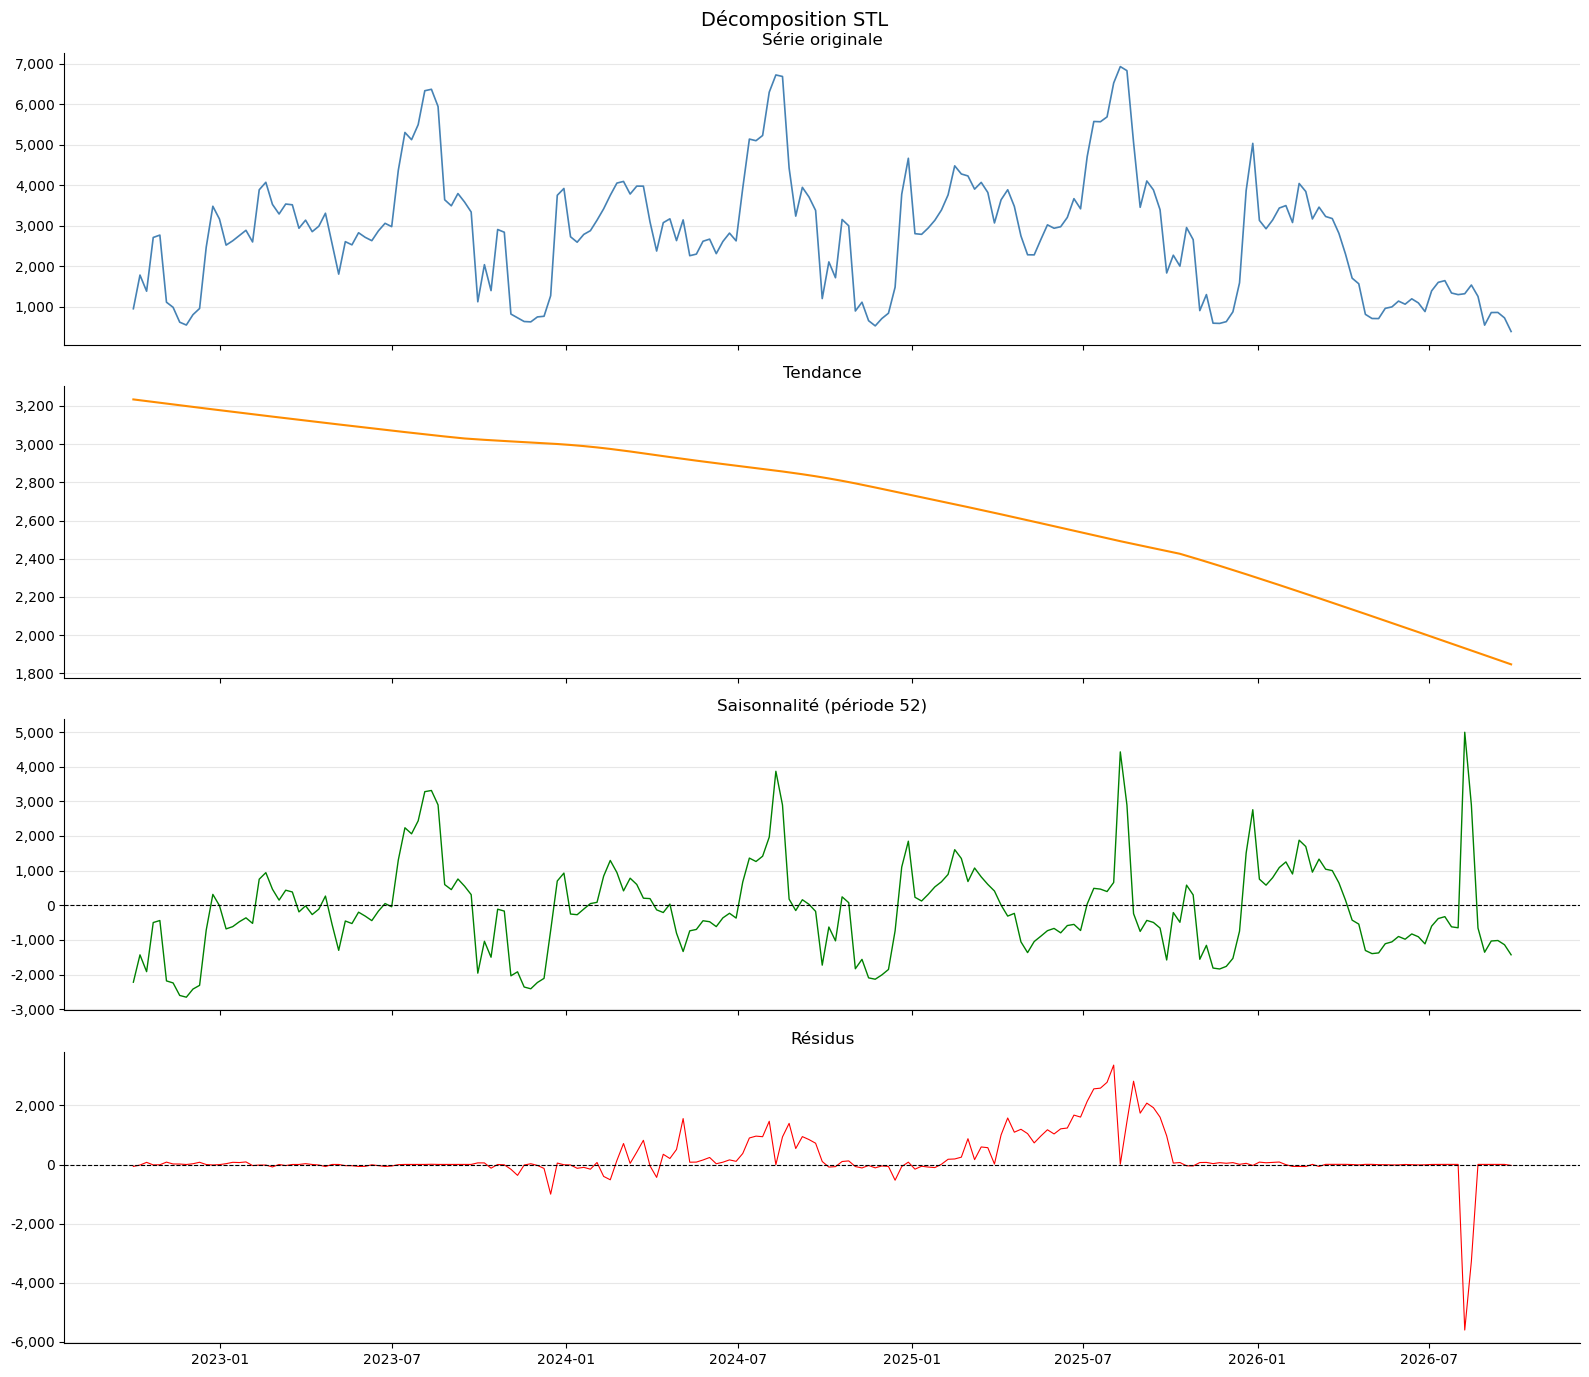

Force de la tendance     : 0.198  (0=nulle, 1=forte)
Force de la saisonnalité : 0.699  (0=nulle, 1=forte)


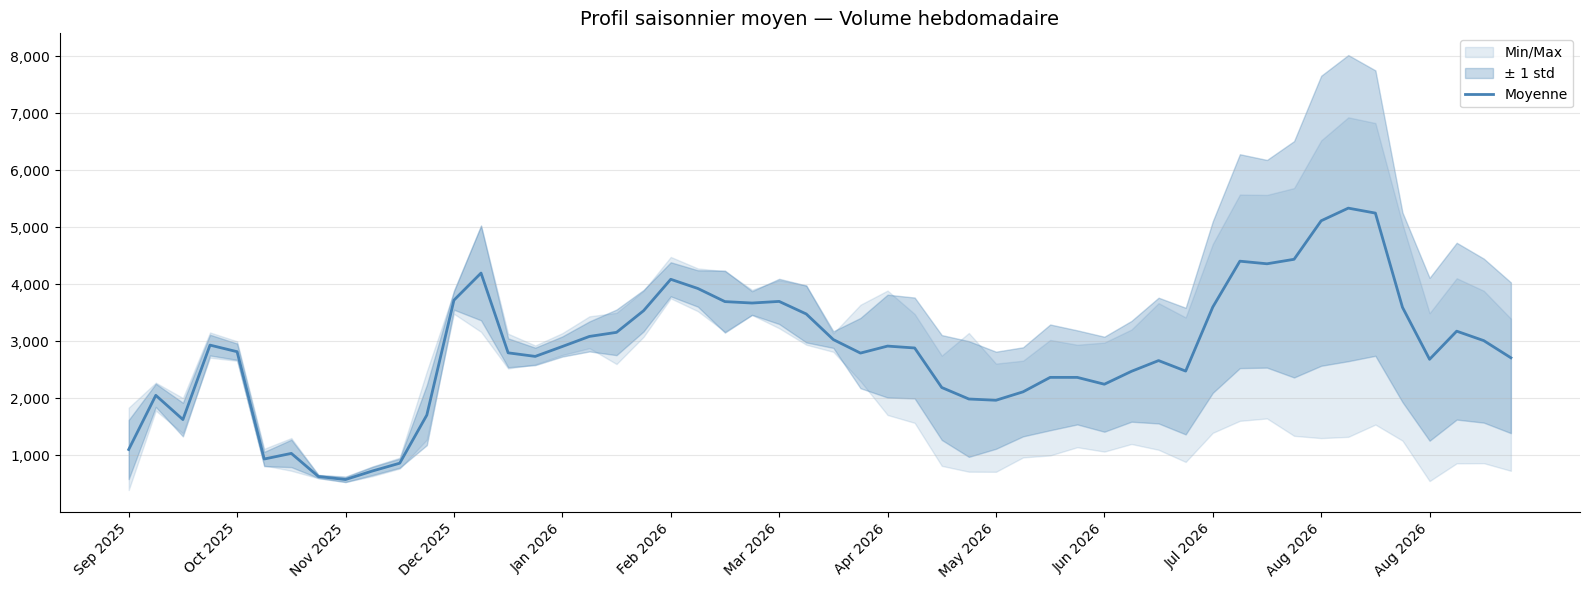

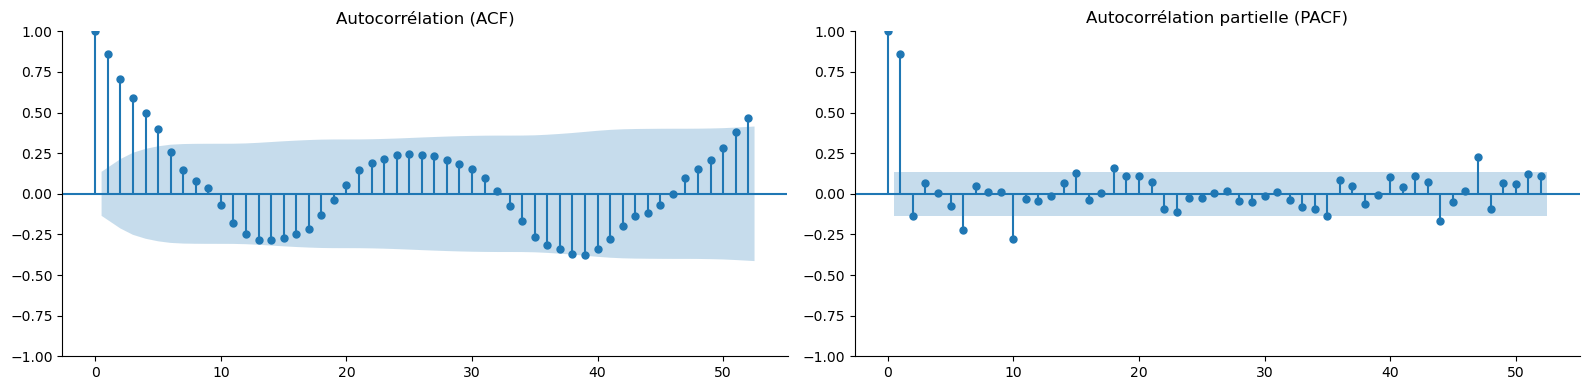


=== Volume moyen par saison ===
                   mean     std    min     max
SAISON                                        
Eté (Avr-Sep)    3085.0  1668.0  387.0  6929.0
Hiver (Oct-Mar)  2577.0  1223.0  526.0  5034.0

=== Volume moyen par mois ===
MOIS
1     2916.0
2     3655.0
3     3554.0
4     2719.0
5     2098.0
6     2459.0
7     4128.0
8     4442.0
9     2565.0
10    2272.0
11     776.0
12    2414.0
Name: VOLUME, dtype: float64


In [38]:
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ============================================================
# 1. DECOMPOSITION STL
# ============================================================
ts = df_prophet.set_index('ds')['y'].asfreq('W-SAT')
stl = STL(ts, period=52, robust=True)
result = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(16, 14), sharex=True)
axes[0].plot(ts, color='steelblue', linewidth=1.2)
axes[0].set_title('Série originale')
axes[1].plot(result.trend, color='darkorange', linewidth=1.5)
axes[1].set_title('Tendance')
axes[2].plot(result.seasonal, color='green', linewidth=1)
axes[2].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[2].set_title('Saisonnalité (période 52)')
axes[3].plot(result.resid, color='red', linewidth=0.8)
axes[3].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[3].set_title('Résidus')
for ax in axes:
    ax.grid(axis='y', alpha=0.3)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.suptitle('Décomposition STL', fontsize=14)
plt.tight_layout()
plt.show()

# ============================================================
# 2. FORCE TENDANCE ET SAISONNALITE
# ============================================================
var_resid = result.resid.var()
force_tendance = max(0, 1 - var_resid / (result.trend + result.resid).var())
force_saisonnalite = max(0, 1 - var_resid / (result.seasonal + result.resid).var())
print(f"Force de la tendance     : {force_tendance:.3f}  (0=nulle, 1=forte)")
print(f"Force de la saisonnalité : {force_saisonnalite:.3f}  (0=nulle, 1=forte)")

# ============================================================
# 3. PROFIL SAISONNIER MOYEN
# ============================================================
semaines_ordre = list(range(39, 53)) + list(range(1, 39))
pos_map = {s: i+1 for i, s in enumerate(semaines_ordre)}

profil = (
    serie_continue
    .groupby('WEEK_ISO')['VOLUME']
    .agg(['mean', 'std', 'min', 'max'])
    .reset_index()
)
profil['POSITION'] = profil['WEEK_ISO'].map(pos_map)
profil = profil.sort_values('POSITION')

mois_ref = (
    data_temp[['WEEK_ISO', 'SEMAINE_SEJOUR']]
    .drop_duplicates('WEEK_ISO')
    .assign(POSITION=lambda x: x['WEEK_ISO'].map(pos_map))
    .assign(MOIS=lambda x: x['SEMAINE_SEJOUR'].dt.strftime('%b %Y'))
    .sort_values('POSITION')
)
tick_pos = mois_ref.iloc[::4]['POSITION'].tolist()
tick_lab = mois_ref.iloc[::4]['MOIS'].tolist()

fig, ax = plt.subplots(figsize=(16, 6))
ax.fill_between(profil['POSITION'], profil['min'], profil['max'],
                alpha=0.15, color='steelblue', label='Min/Max')
ax.fill_between(profil['POSITION'],
                profil['mean'] - profil['std'],
                profil['mean'] + profil['std'],
                alpha=0.3, color='steelblue', label='± 1 std')
ax.plot(profil['POSITION'], profil['mean'],
        color='steelblue', linewidth=2, label='Moyenne')
ax.set_title('Profil saisonnier moyen — Volume hebdomadaire', fontsize=14)
ax.set_xticks(tick_pos)
ax.set_xticklabels(tick_lab, rotation=45, ha='right')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 4. ACF — AUTOCORRELATION
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(ts, lags=52, ax=axes[0], title='Autocorrélation (ACF)')
plot_pacf(ts, lags=52, ax=axes[1], title='Autocorrélation partielle (PACF)')
plt.tight_layout()
plt.show()

# ============================================================
# 5. STATISTIQUES DESCRIPTIVES PAR PERIODE
# ============================================================
serie_continue['MOIS'] = pd.to_datetime(serie_continue['DATE']).dt.month
serie_continue['SAISON'] = serie_continue['MOIS'].apply(
    lambda m: 'Hiver (Oct-Mar)' if m in [10,11,12,1,2,3] else 'Eté (Avr-Sep)'
)

print("\n=== Volume moyen par saison ===")
print(serie_continue.groupby('SAISON')['VOLUME'].agg(['mean','std','min','max']).round(0))

print("\n=== Volume moyen par mois ===")
print(serie_continue.groupby('MOIS')['VOLUME'].mean().round(0))

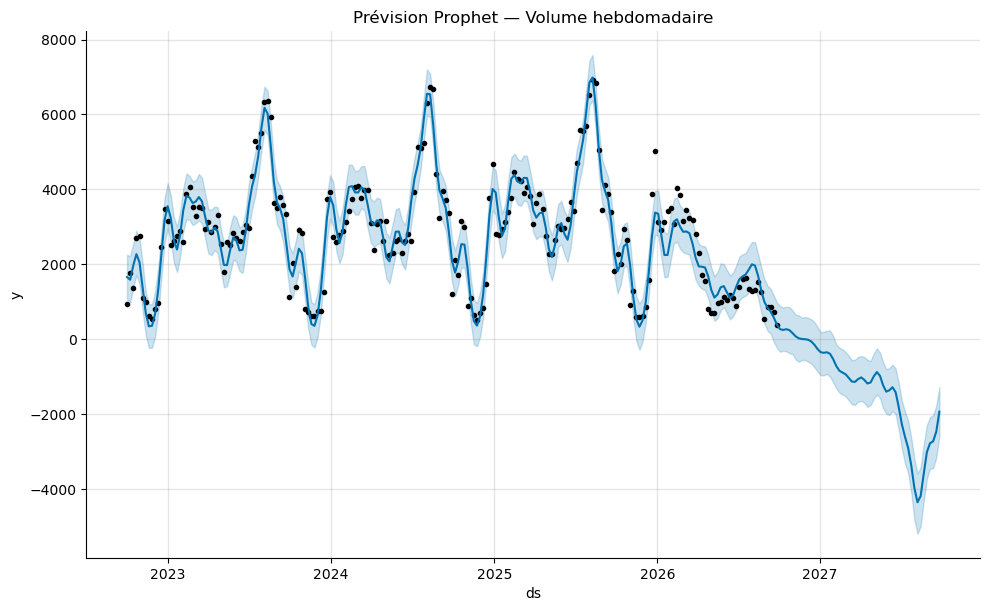

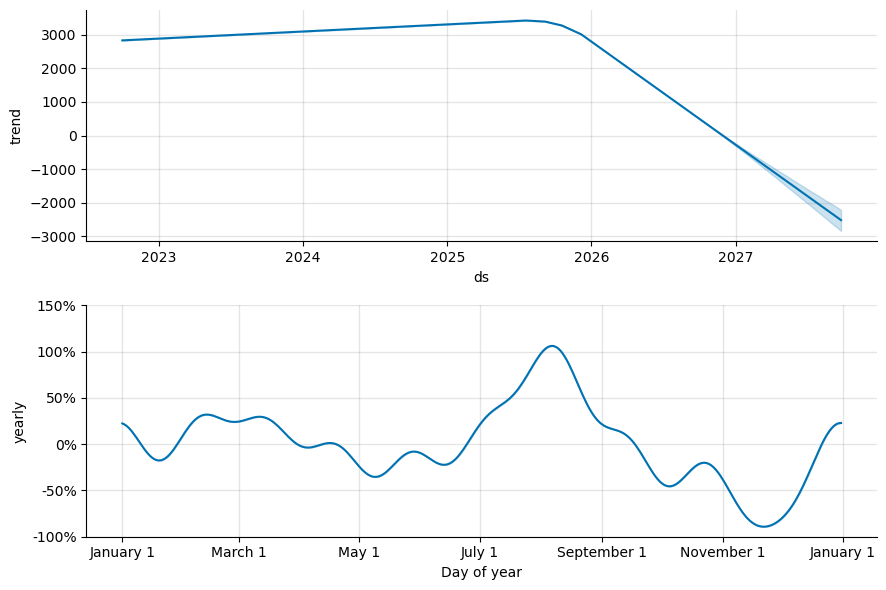

In [39]:
# Créer les dates futures : on prédit 52 semaines
future = model.make_future_dataframe(periods=52, freq='W-SAT')

forecast = model.predict(future)

# Visualisation
fig = model.plot(forecast)
plt.title('Prévision Prophet — Volume hebdomadaire')
plt.show()

# Composantes
fig2 = model.plot_components(forecast)
plt.show()

#### **PROPHET - SERIES PAR ETABLISSEMENT**

**Stratégie multi-établissements par normalisation**

Prophet modélise une série à la fois. Face à 104 établissements aux volumes très hétérogènes, une stratégie de normalisation a été adoptée plutôt que d'entraîner 104 modèles indépendants.

Cette approche repose sur l'hypothèse que tous les établissements partagent le même profil saisonnier relatif — seul le niveau absolu diffère. On décompose donc le volume en deux composantes : le niveau moyen propre à chaque établissement, et le profil saisonnier commun.

Dans un premier temps, chaque série est normalisée par la moyenne historique de l'établissement, ce qui ramène tous les établissements autour d'une valeur de 1.0. Prophet est ensuite entraîné sur la moyenne de ces séries normalisées, apprenant ainsi le profil saisonnier commun à l'ensemble du parc. Enfin, les prévisions sont dénormalisées en les multipliant par la moyenne de chaque établissement, pour revenir à des volumes réels.

In [40]:
data_temp = (
    data
    .groupby(['ID_ETABLISSEMENT', 'SEMAINE_SEJOUR'])
    .agg(
        CA_N=('CA_N', 'sum'),
        VOLUME_N=('VOLUME_N', 'sum'),
        CA_N1DATE=('CA_N1DATE', 'sum'),
        VOLUME_N1DATE=('VOLUME_N1DATE', 'sum'),
        CA_N2DATE=('CA_N2DATE', 'sum'),
        VOLUME_N2DATE=('VOLUME_N2DATE', 'sum'),
        CA_N3DATE=('CA_N3DATE', 'sum'),
        VOLUME_N3DATE=('VOLUME_N3DATE', 'sum'),
    )
    .reset_index()
)

data_temp['SEMAINE_SEJOUR'] = pd.to_datetime(data_temp['SEMAINE_SEJOUR'])
data_temp = data_temp.sort_values(['ID_ETABLISSEMENT', 'SEMAINE_SEJOUR']).reset_index(drop=True)

iso = data_temp['SEMAINE_SEJOUR'].dt.isocalendar()
data_temp['WEEK_ISO'] = iso.week.astype(int)
data_temp['YEAR_N'] = iso.year.astype(int)

print(data_temp['ID_ETABLISSEMENT'].nunique())  # doit afficher 104
print(data_temp.shape)

104
(4171, 12)


In [41]:
from isoweek import Week

frames = []

# Année N
df_n = data_temp[['ID_ETABLISSEMENT', 'SEMAINE_SEJOUR', 'WEEK_ISO', 'YEAR_N', 'VOLUME_N', 'CA_N']].copy()
df_n.columns = ['ID_ETABLISSEMENT', 'DATE', 'WEEK_ISO', 'YEAR_N', 'VOLUME', 'CA']
df_n['ANNEE'] = 'N'
frames.append(df_n)

# Années N-1, N-2, N-3
for i, label in enumerate(['N1', 'N2', 'N3'], start=1):
    vol_col = f'VOLUME_{label}DATE'
    ca_col = f'CA_{label}DATE'
    
    df = data_temp[['ID_ETABLISSEMENT', 'WEEK_ISO', 'YEAR_N', vol_col, ca_col]].copy()
    df.columns = ['ID_ETABLISSEMENT', 'WEEK_ISO', 'YEAR_N', 'VOLUME', 'CA']
    df['ANNEE'] = f'N-{i}'
    df['DATE'] = df.apply(
        lambda row: pd.Timestamp(Week(row['YEAR_N'] - i, row['WEEK_ISO']).saturday()), axis=1
    )
    frames.append(df[['ID_ETABLISSEMENT', 'DATE', 'WEEK_ISO', 'YEAR_N', 'VOLUME', 'CA', 'ANNEE']])

serie_continue = (
    pd.concat(frames)
    .sort_values(['ID_ETABLISSEMENT', 'DATE'])
    .drop_duplicates(subset=['ID_ETABLISSEMENT', 'DATE'], keep='first')
    .reset_index(drop=True)
)

print(serie_continue.groupby('ANNEE')['VOLUME'].sum())
print(serie_continue['ID_ETABLISSEMENT'].nunique())
print(len(serie_continue))

ANNEE
N      99203.833073
N-1    96456.112465
N-2    89856.440041
N-3    85915.594558
Name: VOLUME, dtype: float64
104
16501


In [42]:
# Moyenne par établissement pour normalisation
moyennes = (
    serie_continue
    .groupby('ID_ETABLISSEMENT')['VOLUME']
    .mean()
    .rename('VOLUME_MOYEN')
    .reset_index()
)

serie_continue = serie_continue.merge(moyennes, on='ID_ETABLISSEMENT', how='left')

# Normalisation : volume relatif à la moyenne de l'établissement
serie_continue['VOLUME_NORM'] = serie_continue['VOLUME'] / serie_continue['VOLUME_MOYEN']

# Dataset Prophet : une ligne par date, moyenne des volumes normalisés
df_prophet = (
    serie_continue
    .groupby('DATE')['VOLUME_NORM']
    .mean()
    .reset_index()
)
df_prophet.columns = ['ds', 'y']
df_prophet = df_prophet.sort_values('ds').reset_index(drop=True)

print(df_prophet.shape)
print(df_prophet.describe())

(209, 2)
                        ds           y
count                  209  209.000000
mean   2024-09-28 00:00:00    1.000633
min    2022-10-01 00:00:00    0.284468
25%    2023-09-30 00:00:00    0.646105
50%    2024-09-28 00:00:00    0.823959
75%    2025-09-27 00:00:00    1.273447
max    2026-09-26 00:00:00    2.864282
std                    NaN    0.521414


23:19:34 - cmdstanpy - INFO - Chain [1] start processing
23:19:34 - cmdstanpy - INFO - Chain [1] done processing


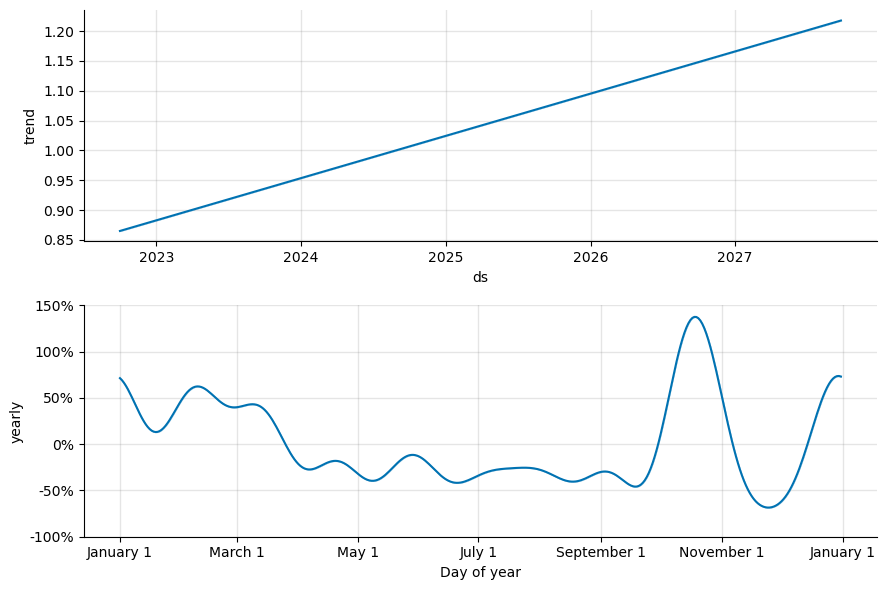

In [43]:
from prophet import Prophet

model = Prophet(
    seasonality_mode='multiplicative',
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
)

model.fit(df_prophet)

# Prévision sur 52 semaines futures
future = model.make_future_dataframe(periods=52, freq='W-SAT')
forecast = model.predict(future)

# Visualisation composantes
fig = model.plot_components(forecast)
plt.show()

En mode multiplicative, Prophet exprime la saisonnalité comme un pourcentage de variation autour de la tendance :

+100% → la demande est 2x la moyenne (pic fort)
0% → la demande est exactement à la moyenne
-50% → la demande est à 50% de la moyenne (creux)

Donc ce que tu lis c'est : "par rapport à la tendance de base, cette semaine la demande est X% plus haute ou plus basse".

In [44]:
# Prévisions dénormalisées par établissement
resultats = []

for etab_id, groupe in serie_continue.groupby('ID_ETABLISSEMENT'):
    volume_moyen = groupe['VOLUME_MOYEN'].iloc[0]
    
    # Dénormaliser : forecast normalisé × moyenne de l'établissement
    df_etab = forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].copy()
    df_etab['VOLUME_PREVU'] = df_etab['yhat'] * volume_moyen
    df_etab['VOLUME_PREVU_LOW'] = df_etab['yhat_lower'] * volume_moyen
    df_etab['VOLUME_PREVU_HIGH'] = df_etab['yhat_upper'] * volume_moyen
    df_etab['ID_ETABLISSEMENT'] = etab_id
    
    resultats.append(df_etab)

df_previsions = pd.concat(resultats).reset_index(drop=True)

print(df_previsions.shape)
print(df_previsions.head())

(27144, 8)
          ds      yhat  yhat_lower  yhat_upper  VOLUME_PREVU  \
0 2022-10-01  0.940561    0.624730    1.265483     53.983603   
1 2022-10-08  1.535375    1.231207    1.844486     88.123022   
2 2022-10-15  1.990923    1.685666    2.292384    114.269280   
3 2022-10-22  2.006969    1.686796    2.312253    115.190220   
4 2022-10-29  1.583171    1.276288    1.893967     90.866308   

   VOLUME_PREVU_LOW  VOLUME_PREVU_HIGH ID_ETABLISSEMENT  
0         35.856470          72.632524                1  
1         70.665273         105.864466                1  
2         96.748989         131.571673                1  
3         96.813841         132.712052                1  
4         73.252675         108.704444                1  


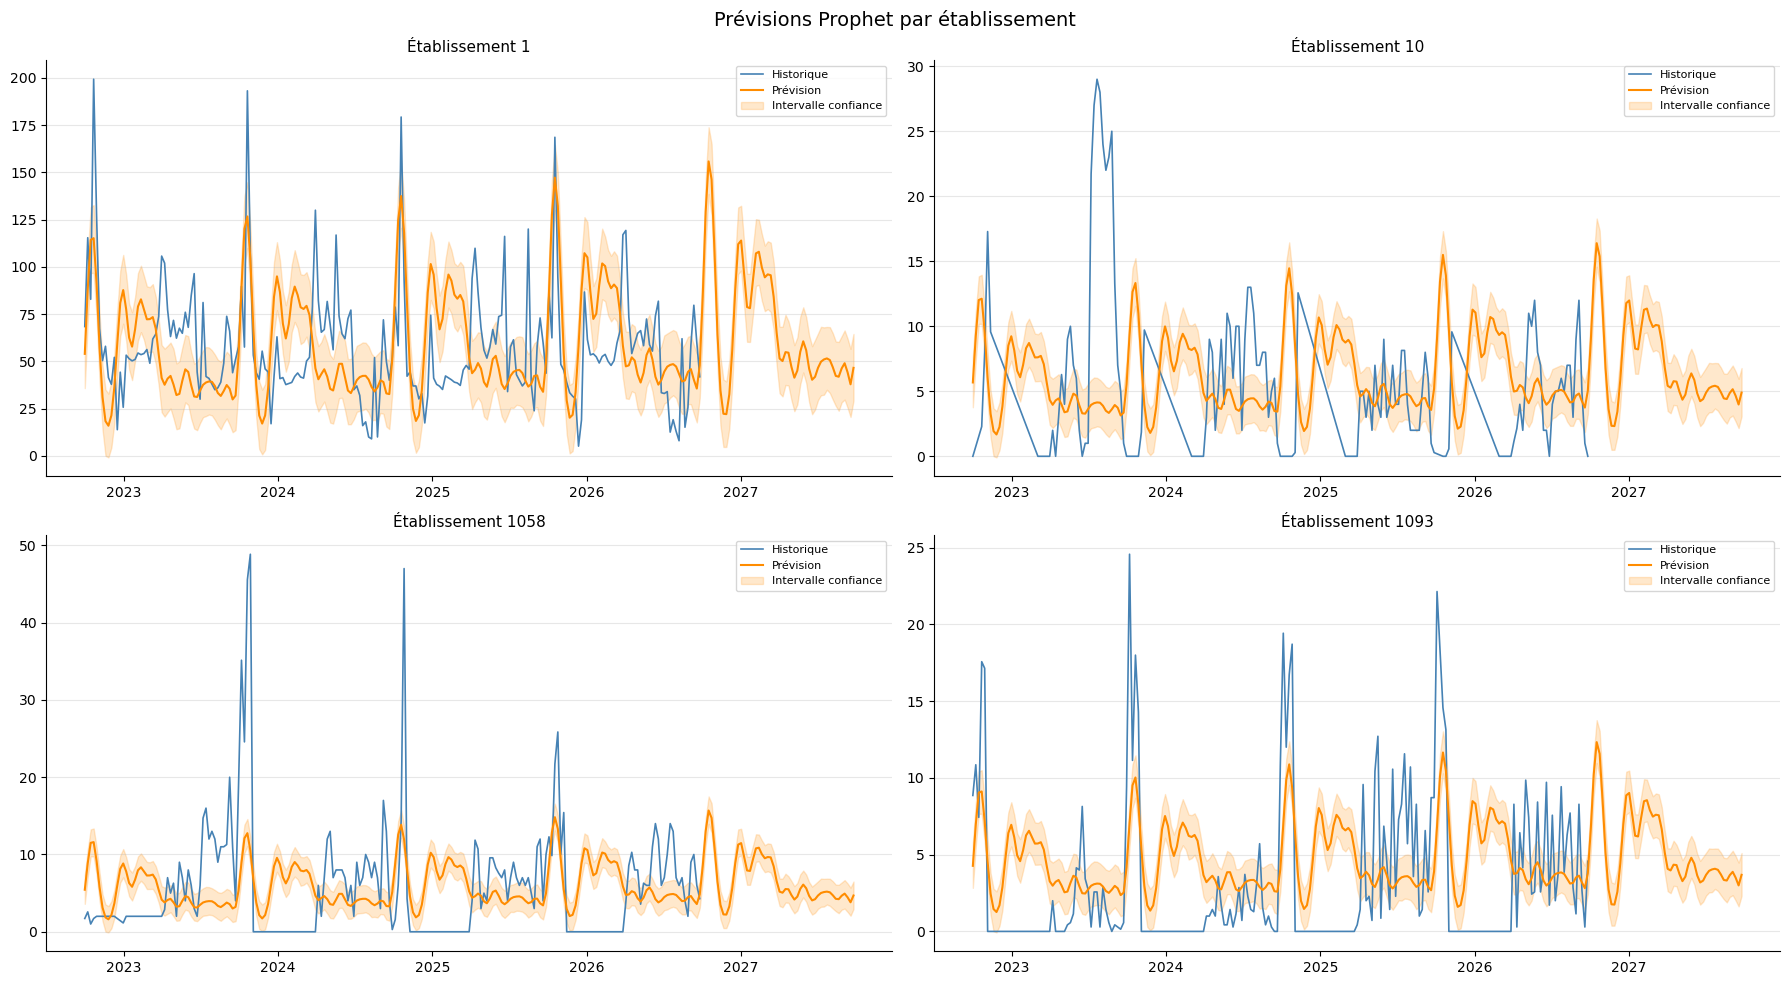

=== Qualité du modèle ===
MAE  moyenne : 12.5
MAPE moyenne : -481115570284884.6%
MAPE médiane : 127.6%

Top 10 établissements avec la plus forte erreur :
   ID_ETABLISSEMENT        MAE          MAPE
70             2545   8.130161  2.458448e+17
36             1848   8.556902  5.563588e+16
7                13   8.285024  5.268057e+16
41             1998   4.904550  5.015022e+16
14              150   2.258854  4.235564e+16
27             1821  69.957136  2.594675e+03
74             2896  19.956712  1.218921e+03
73             2894  50.687510  1.023876e+03
38             1903  13.351352  9.687790e+02
29             1824  24.361994  7.562333e+02


In [45]:
# ============================================================
# 1. VISUALISATION — quelques établissements en exemple
# ============================================================
etabs_sample = serie_continue['ID_ETABLISSEMENT'].unique()[:4]

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()

for idx, etab_id in enumerate(etabs_sample):
    ax = axes[idx]
    
    # Historique réel
    hist = serie_continue[serie_continue['ID_ETABLISSEMENT'] == etab_id].sort_values('DATE')
    ax.plot(hist['DATE'], hist['VOLUME'], color='steelblue', linewidth=1.2, label='Historique')
    
    # Prévision
    prev = df_previsions[df_previsions['ID_ETABLISSEMENT'] == etab_id].sort_values('ds')
    ax.plot(prev['ds'], prev['VOLUME_PREVU'], color='darkorange', linewidth=1.5, label='Prévision')
    ax.fill_between(prev['ds'], prev['VOLUME_PREVU_LOW'], prev['VOLUME_PREVU_HIGH'],
                    alpha=0.2, color='darkorange', label='Intervalle confiance')
    
    ax.set_title(f'Établissement {etab_id}', fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.suptitle('Prévisions Prophet par établissement', fontsize=14)
plt.tight_layout()
plt.show()

# ============================================================
# 2. EVALUATION — MAE et MAPE sur l'historique connu
# ============================================================
from sklearn.metrics import mean_absolute_error
import numpy as np

erreurs = []

for etab_id, groupe in serie_continue.groupby('ID_ETABLISSEMENT'):
    volume_moyen = groupe['VOLUME_MOYEN'].iloc[0]
    
    # Fusionner historique et prévision sur les dates communes
    hist = groupe[['DATE', 'VOLUME']].rename(columns={'DATE': 'ds'})
    prev = df_previsions[df_previsions['ID_ETABLISSEMENT'] == etab_id][['ds', 'VOLUME_PREVU']]
    merged = hist.merge(prev, on='ds', how='inner')
    
    if len(merged) > 0:
        mae = mean_absolute_error(merged['VOLUME'], merged['VOLUME_PREVU'])
        mape = (np.abs(merged['VOLUME'] - merged['VOLUME_PREVU']) / merged['VOLUME'].replace(0, np.nan)).mean() * 100
        erreurs.append({'ID_ETABLISSEMENT': etab_id, 'MAE': mae, 'MAPE': mape})

df_erreurs = pd.DataFrame(erreurs)
print("=== Qualité du modèle ===")
print(f"MAE  moyenne : {df_erreurs['MAE'].mean():.1f}")
print(f"MAPE moyenne : {df_erreurs['MAPE'].mean():.1f}%")
print(f"MAPE médiane : {df_erreurs['MAPE'].median():.1f}%")
print(f"\nTop 10 établissements avec la plus forte erreur :")
print(df_erreurs.nlargest(10, 'MAPE')[['ID_ETABLISSEMENT', 'MAE', 'MAPE']])

### **APPROCHE ML - XG BOOST**

In [46]:
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_error

#### **Prévisions à l'échelle macro**

In [47]:
data_temp = (
    data
    .groupby(['SEMAINE_SEJOUR'])
    .agg(
        CA_N=('CA_N', 'sum'),
        VOLUME_N=('VOLUME_N', 'sum'),
        CA_N1=('CA_N1FDS', 'sum'),
        VOLUME_N1=('VOLUME_N1FDS', 'sum'),
        CA_N2=('CA_N2FDS', 'sum'),
        VOLUME_N2=('VOLUME_N2FDS', 'sum'),
        CA_N3=('CA_N3FDS', 'sum'),
        VOLUME_N3=('VOLUME_N3FDS', 'sum'),
        
    
    )
    .reset_index()
)

data_temp['PRIX_MOYEN_N']  = data_temp['CA_N']      / data_temp['VOLUME_N']
data_temp['PRIX_MOYEN_N1'] = data_temp['CA_N1']  / data_temp['VOLUME_N1']
data_temp['PRIX_MOYEN_N2'] = data_temp['CA_N2']  / data_temp['VOLUME_N2']
data_temp['PRIX_MOYEN_N3'] = data_temp['CA_N3']  / data_temp['VOLUME_N3']

data_temp['SEMAINE_SEJOUR'] = pd.to_datetime(data_temp['SEMAINE_SEJOUR'])
data_temp = data_temp.sort_values(['SEMAINE_SEJOUR']).reset_index(drop=True)

iso = data_temp['SEMAINE_SEJOUR'].dt.isocalendar()
data_temp['WEEK_ISO'] = iso.week.astype(int)
data_temp['YEAR_N'] = iso.year.astype(int)

print(data_temp.shape)

(53, 15)


In [48]:
from isoweek import Week

frames = []

# Année N
df_n = data_temp[['SEMAINE_SEJOUR', 'WEEK_ISO', 'YEAR_N', 'VOLUME_N', 'CA_N', 'PRIX_MOYEN_N']].copy()
df_n.columns = ['DATE', 'WEEK_ISO', 'YEAR_N', 'VOLUME', 'CA', 'PRIX_MOYEN']
df_n['ANNEE'] = 'N'
frames.append(df_n)

# Années N-1, N-2, N-3
for i, label in enumerate(['N1', 'N2', 'N3'], start=1):
    vol_col = f'VOLUME_{label}'
    ca_col  = f'CA_{label}'
    px_col  = f'PRIX_MOYEN_N{i}'
    
    df = data_temp[['WEEK_ISO', 'YEAR_N', vol_col, ca_col, px_col]].copy()
    df.columns = ['WEEK_ISO', 'YEAR_N', 'VOLUME', 'CA', 'PRIX_MOYEN']
    df['ANNEE'] = f'N-{i}'
    df['DATE'] = df.apply(
        lambda row: pd.Timestamp(Week(row['YEAR_N'] - i, row['WEEK_ISO']).saturday()), axis=1
    )
    frames.append(df[['DATE', 'WEEK_ISO', 'YEAR_N', 'VOLUME', 'CA', 'PRIX_MOYEN', 'ANNEE']])

serie_continue = (
    pd.concat(frames)
    .sort_values(['DATE'])
    .drop_duplicates(subset=['DATE'], keep='first')
    .reset_index(drop=True)
)

print(serie_continue.groupby('ANNEE')['VOLUME'].sum())
print(len(serie_continue))
serie = serie_continue

ANNEE
N       99203.833073
N-1    173188.506848
N-2    160970.669714
N-3    159401.240978
Name: VOLUME, dtype: float64
209


In [49]:
df_xgb = df_xgb = serie[['DATE','VOLUME', 'PRIX_MOYEN']].copy()
df_xgb = df_xgb.sort_values(['DATE']).reset_index(drop=True)

In [50]:
df_xgb['WEEK_ISO'] = df_xgb['DATE'].dt.isocalendar().week.astype(int)
df_xgb['MONTH'] = df_xgb['DATE'].dt.month
df_xgb['YEAR'] = df_xgb['DATE'].dt.isocalendar().year.astype(int)

In [51]:
semaines_ordre = list(range(39, 53)) + list(range(1, 39))
pos_map = {s: i+1 for i, s in enumerate(semaines_ordre)}
df_xgb['POSITION_SAISON'] = df_xgb['WEEK_ISO'].map(pos_map)

In [52]:
df_xgb['SAISON'] = df_xgb['MONTH'].apply(
    lambda m: 1 if m in [10, 11, 12, 1, 2, 3] else 0)

In [53]:
# --- Lags ---
for lag in [1, 2, 3, 4, 5, 7, 9, 15, 26, 52]:
    df_xgb[f'lag_{lag}'] = df_xgb["VOLUME"].shift(lag)

In [54]:
# Supprimer les lignes avec NaN (dues aux lags)
df_xgb = df_xgb.dropna().reset_index(drop=True)

print(df_xgb.shape)
print(df_xgb.columns.tolist())

(157, 18)
['DATE', 'VOLUME', 'PRIX_MOYEN', 'WEEK_ISO', 'MONTH', 'YEAR', 'POSITION_SAISON', 'SAISON', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_7', 'lag_9', 'lag_15', 'lag_26', 'lag_52']


In [55]:
df_xgb.head()

,DATE,VOLUME,PRIX_MOYEN,WEEK_ISO,MONTH,YEAR,POSITION_SAISON,SAISON,lag_1,lag_2,lag_3,lag_4,lag_5,lag_7,lag_9,lag_15,lag_26,lag_52
0,2023-09-30,1889.287973,336.970526,39,9,2023,1,0,3337.861093,3584.862517,3794.149546,3491.291072,3640.432113,6368.581496,5495.435774,2873.289119,3137.000657,949.572776
1,2023-10-07,2037.859335,333.423670,40,10,2023,2,1,1889.287973,3337.861093,3584.862517,3794.149546,3491.291072,5942.720762,6333.151740,3059.003526,2852.570904,1780.859429
2,2023-10-14,1396.858614,336.869076,41,10,2023,3,1,2037.859335,1889.287973,3337.861093,3584.862517,3794.149546,3640.432113,6368.581496,2976.860276,2987.427993,1382.144203
3,2023-10-21,2905.857498,384.205552,42,10,2023,4,1,1396.858614,2037.859335,1889.287973,3337.861093,3584.862517,3491.291072,5942.720762,4369.006204,3307.856632,2709.571106
4,2023-10-28,2838.856948,385.664016,43,10,2023,5,1,2905.857498,1396.858614,2037.859335,1889.287973,3337.861093,3794.149546,3640.432113,5302.581201,2556.428418,2767.999124


In [56]:
FEATURES = [
    'WEEK_ISO', 'MONTH', 'POSITION_SAISON', 'SAISON', 'PRIX_MOYEN',
    'lag_1',  'lag_2', 'lag_3', 'lag_5', 'lag_4', 'lag_7', 'lag_9', 'lag_15', 'lag_26', 'lag_52'
]

TARGET = 'VOLUME'

In [57]:
# Modèle de base
model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    random_state=42,
    n_jobs=-1,
    enable_categorical=True
)

In [58]:
train_years = [2023, 2024]
test_year = 2025

train_mask = df_xgb['YEAR'].isin(train_years)
test_mask  = df_xgb['YEAR'].eq(test_year)

X_train = df_xgb.loc[train_mask, FEATURES]
y_train = df_xgb.loc[train_mask, TARGET]

X_test  = df_xgb.loc[test_mask, FEATURES]
y_test  = df_xgb.loc[test_mask, TARGET]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Années train:", df_xgb.loc[train_mask, 'YEAR'].value_counts().sort_index().to_dict())
print("Année test:", df_xgb.loc[test_mask, 'YEAR'].value_counts().sort_index().to_dict())


Train: (66, 15) Test: (52, 15)
Années train: {2023: 14, 2024: 52}
Année test: {2025: 52}


In [59]:
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)

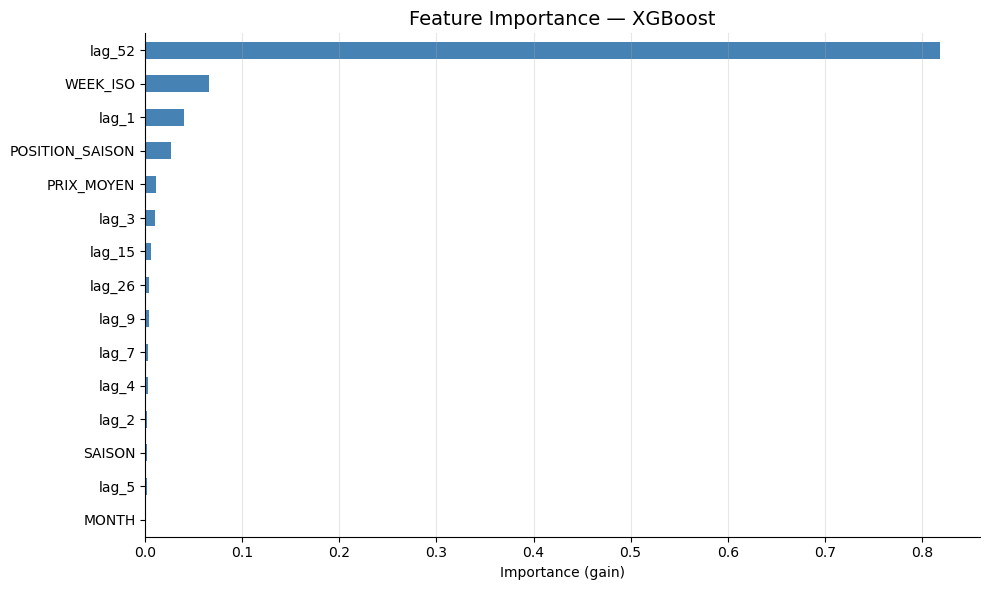

In [60]:
# 1. FEATURE IMPORTANCE
feat_imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
feat_imp.plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Feature Importance — XGBoost', fontsize=14)
ax.set_xlabel('Importance (gain)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [61]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
# 2. EVALUATION TRAIN / TEST

preds_train = model.predict(X_train)
preds_test  = model.predict(X_test)

mae_train  = mean_absolute_error(y_train, preds_train)
mae_test   = mean_absolute_error(y_test, preds_test)
rmse_train = np.sqrt(mean_squared_error(y_train, preds_train))
rmse_test  = np.sqrt(mean_squared_error(y_test, preds_test))

print("=== Évaluation du modèle ===")
print(f"MAE  Train : {mae_train:.2f}  |  MAE  Test : {mae_test:.2f}")
print(f"RMSE Train : {rmse_train:.2f}  |  RMSE Test : {rmse_test:.2f}")
print(f"Ratio MAE Test/Train : {mae_test/mae_train:.2f}  (proche de 1 = pas d'overfitting)")


=== Évaluation du modèle ===
MAE  Train : 0.27  |  MAE  Test : 334.12
RMSE Train : 0.33  |  RMSE Test : 452.49
Ratio MAE Test/Train : 1237.17  (proche de 1 = pas d'overfitting)


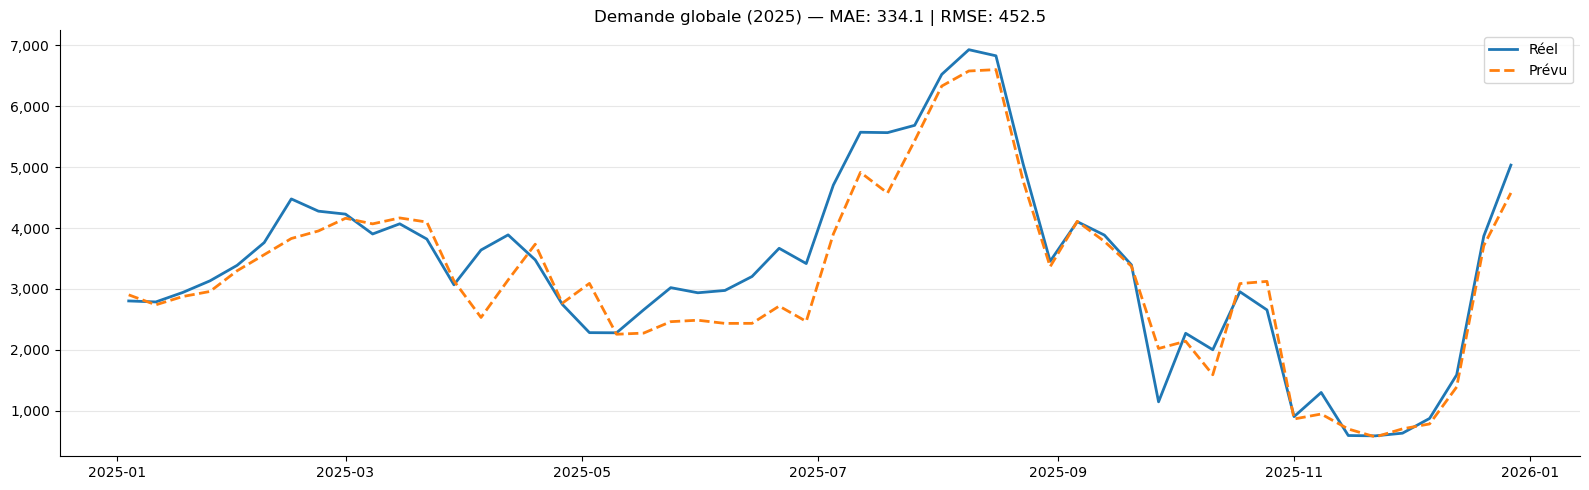

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Prédictions
preds_test = model.predict(X_test)

# DataFrame de test avec DATE + VOLUME
test_plot = df_xgb.loc[test_mask, ['DATE', TARGET]].copy()
test_plot.rename(columns={TARGET: 'VOLUME'}, inplace=True)
test_plot['PREDICTIONS'] = preds_test

test_plot['DATE'] = pd.to_datetime(test_plot['DATE'])

macro = (
    test_plot
    .groupby('DATE', as_index=False)[['VOLUME', 'PREDICTIONS']]
    .sum()
    .sort_values('DATE')
)

mae  = mean_absolute_error(macro['VOLUME'], macro['PREDICTIONS'])
rmse = np.sqrt(mean_squared_error(macro['VOLUME'], macro['PREDICTIONS']))

plt.figure(figsize=(16, 5))
plt.plot(macro['DATE'], macro['VOLUME'], linewidth=2, label='Réel')
plt.plot(macro['DATE'], macro['PREDICTIONS'], linewidth=2, linestyle='--', label='Prévu')
plt.title(f"Demande globale (2025) — MAE: {mae:.1f} | RMSE: {rmse:.1f}")
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

#### **Prévisions avec 2VAR**

In [63]:
VAR = 'ETABLISSEMENT_TYPE'

In [64]:
data_temp = (
    data
    .groupby([VAR, 'SEMAINE_SEJOUR'])
    .agg(
        CA_N=('CA_N', 'sum'),
        VOLUME_N=('VOLUME_N', 'sum'),
        CA_N1DATE=('CA_N1FDS', 'sum'),
        VOLUME_N1DATE=('VOLUME_N1FDS', 'sum'),
        CA_N2DATE=('CA_N2FDS', 'sum'),
        VOLUME_N2DATE=('VOLUME_N2FDS', 'sum'),
        CA_N3DATE=('CA_N3FDS', 'sum'),
        VOLUME_N3DATE=('VOLUME_N3FDS', 'sum'),
    
    )
    .reset_index()
)

data_temp['PRIX_MOYEN_N']  = data_temp['CA_N']      / data_temp['VOLUME_N']
data_temp['PRIX_MOYEN_N1'] = data_temp['CA_N1DATE']  / data_temp['VOLUME_N1DATE']
data_temp['PRIX_MOYEN_N2'] = data_temp['CA_N2DATE']  / data_temp['VOLUME_N2DATE']
data_temp['PRIX_MOYEN_N3'] = data_temp['CA_N3DATE']  / data_temp['VOLUME_N3DATE']

data_temp['SEMAINE_SEJOUR'] = pd.to_datetime(data_temp['SEMAINE_SEJOUR'])
data_temp = data_temp.sort_values(['SEMAINE_SEJOUR', VAR ]).reset_index(drop=True)

iso = data_temp['SEMAINE_SEJOUR'].dt.isocalendar()
data_temp['WEEK_ISO'] = iso.week.astype(int)
data_temp['YEAR_N'] = iso.year.astype(int)

print(data_temp[VAR].nunique())
print(data_temp.shape)

C:\Users\HP\AppData\Local\Temp\ipykernel_19476\3176185884.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby([VAR, 'SEMAINE_SEJOUR'])


3
(159, 16)


In [65]:
from isoweek import Week

frames = []

# Année N
df_n = data_temp[[VAR, 'SEMAINE_SEJOUR', 'WEEK_ISO', 'YEAR_N', 'VOLUME_N', 'CA_N', 'PRIX_MOYEN_N']].copy()
df_n.columns = [VAR, 'DATE', 'WEEK_ISO', 'YEAR_N', 'VOLUME', 'CA', 'PRIX_MOYEN']
df_n['ANNEE'] = 'N'
frames.append(df_n)

# Années N-1, N-2, N-3
for i, label in enumerate(['N1', 'N2', 'N3'], start=1):
    vol_col = f'VOLUME_{label}DATE'
    ca_col  = f'CA_{label}DATE'
    px_col  = f'PRIX_MOYEN_N{i}'
    
    df = data_temp[[VAR, 'WEEK_ISO', 'YEAR_N', vol_col, ca_col, px_col]].copy()
    df.columns = [VAR, 'WEEK_ISO', 'YEAR_N', 'VOLUME', 'CA', 'PRIX_MOYEN']
    df['ANNEE'] = f'N-{i}'
    df['DATE'] = df.apply(
        lambda row: pd.Timestamp(Week(row['YEAR_N'] - i, row['WEEK_ISO']).saturday()), axis=1
    )
    frames.append(df[[VAR, 'DATE', 'WEEK_ISO', 'YEAR_N', 'VOLUME', 'CA', 'PRIX_MOYEN', 'ANNEE']])

serie_continue = (
    pd.concat(frames)
    .sort_values(['DATE', VAR])
    .drop_duplicates(subset=[VAR, 'DATE'], keep='first')
    .reset_index(drop=True)
)




print(serie_continue.groupby('ANNEE')['VOLUME'].sum())
print(serie_continue[VAR].nunique())
print(len(serie_continue))
serie = serie_continue

ANNEE
N       99203.833073
N-1    174388.650806
N-2    160204.669183
N-3    157511.953005
Name: VOLUME, dtype: float64
3
627


In [66]:
df_xgb = df_xgb = serie[['DATE',VAR, 'VOLUME', 'PRIX_MOYEN']].copy()
df_xgb = df_xgb.sort_values(['DATE', VAR]).reset_index(drop=True)

In [67]:
df_xgb['WEEK_ISO'] = df_xgb['DATE'].dt.isocalendar().week.astype(int)
df_xgb['MONTH'] = df_xgb['DATE'].dt.month
df_xgb['YEAR'] = df_xgb['DATE'].dt.isocalendar().year.astype(int)

In [68]:
semaines_ordre = list(range(39, 53)) + list(range(1, 39))
pos_map = {s: i+1 for i, s in enumerate(semaines_ordre)}
df_xgb['POSITION_SAISON'] = df_xgb['WEEK_ISO'].map(pos_map)

In [69]:
df_xgb['SAISON'] = df_xgb['MONTH'].apply(
    lambda m: 1 if m in [10, 11, 12, 1, 2, 3] else 0)

In [70]:
print(df_xgb[VAR].nunique())
print(df_xgb[VAR].value_counts())

3
ETABLISSEMENT_TYPE
Campagne    209
Mer         209
Montagne    209
Name: count, dtype: int64


In [71]:
# --- Lags par établissement ---
# Important : le shift doit se faire PAR établissement pour ne pas mélanger les séries
for lag in [1, 4, 7, 9, 15, 26, 52]:
    df_xgb[f'lag_{lag}'] = (
        df_xgb.groupby(VAR)['VOLUME'].shift(lag)
    )

C:\Users\HP\AppData\Local\Temp\ipykernel_19476\2166453389.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_xgb.groupby(VAR)['VOLUME'].shift(lag)
C:\Users\HP\AppData\Local\Temp\ipykernel_19476\2166453389.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_xgb.groupby(VAR)['VOLUME'].shift(lag)
C:\Users\HP\AppData\Local\Temp\ipykernel_19476\2166453389.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_xgb.group

In [72]:
# Supprimer les lignes avec NaN (dues aux lags)
df_xgb = df_xgb.dropna().reset_index(drop=True)

print(df_xgb.shape)
print(df_xgb.columns.tolist())

(471, 16)
['DATE', 'ETABLISSEMENT_TYPE', 'VOLUME', 'PRIX_MOYEN', 'WEEK_ISO', 'MONTH', 'YEAR', 'POSITION_SAISON', 'SAISON', 'lag_1', 'lag_4', 'lag_7', 'lag_9', 'lag_15', 'lag_26', 'lag_52']


In [73]:
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_error
import numpy as np

In [74]:
# Encodage du type établissement
from sklearn.preprocessing import LabelEncoder


le = LabelEncoder()
df_xgb[f'{VAR}_ENC'] = le.fit_transform(df_xgb[VAR].astype(str))

In [75]:
FEATURES = [
    'WEEK_ISO', 'MONTH', 'POSITION_SAISON', 'SAISON', f'{VAR}_ENC', 'PRIX_MOYEN',
    'lag_1', 'lag_4', 'lag_7', 'lag_9', 'lag_15', 'lag_26', 'lag_52'
]

TARGET = 'VOLUME'

In [76]:
train_years = [2023, 2024]
test_year = 2025

train = df_xgb['YEAR'].isin(train_years)
test  = df_xgb['YEAR'].eq(test_year)

X_train = df_xgb.loc[train, FEATURES]
y_train = df_xgb.loc[train, TARGET]

X_test  = df_xgb.loc[test, FEATURES]
y_test  = df_xgb.loc[test, TARGET]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Années train:", df_xgb.loc[train, 'YEAR'].value_counts().sort_index().to_dict())
print("Année test:", df_xgb.loc[test, 'YEAR'].value_counts().sort_index().to_dict())


Train: (198, 13) Test: (156, 13)
Années train: {2023: 42, 2024: 156}
Année test: {2025: 156}


In [77]:
# Modèle de base
model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    random_state=42,
    n_jobs=-1,
    enable_categorical=True
)

In [78]:
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)

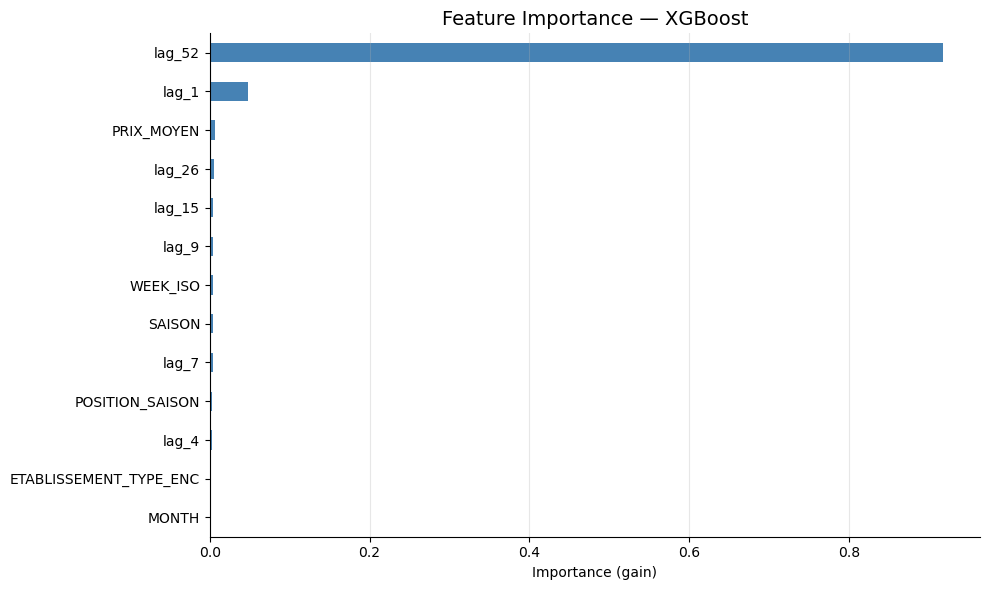

In [79]:
# 1. FEATURE IMPORTANCE
feat_imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
feat_imp.plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Feature Importance — XGBoost', fontsize=14)
ax.set_xlabel('Importance (gain)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [80]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
# 2. EVALUATION TRAIN / TEST

preds_train = model.predict(X_train)
preds_test  = model.predict(X_test)

mae_train  = mean_absolute_error(y_train, preds_train)
mae_test   = mean_absolute_error(y_test, preds_test)
rmse_train = np.sqrt(mean_squared_error(y_train, preds_train))
rmse_test  = np.sqrt(mean_squared_error(y_test, preds_test))

print("=== Évaluation du modèle ===")
print(f"MAE  Train : {mae_train:.2f}  |  MAE  Test : {mae_test:.2f}")
print(f"RMSE Train : {rmse_train:.2f}  |  RMSE Test : {rmse_test:.2f}")
print(f"Ratio MAE Test/Train : {mae_test/mae_train:.2f}  (proche de 1 = pas d'overfitting)")


=== Évaluation du modèle ===
MAE  Train : 3.51  |  MAE  Test : 124.04
RMSE Train : 4.53  |  RMSE Test : 184.97
Ratio MAE Test/Train : 35.36  (proche de 1 = pas d'overfitting)


=== Performance agrégée (tous établissements confondus) ===
MAE  : 294.01
RMSE : 409.95


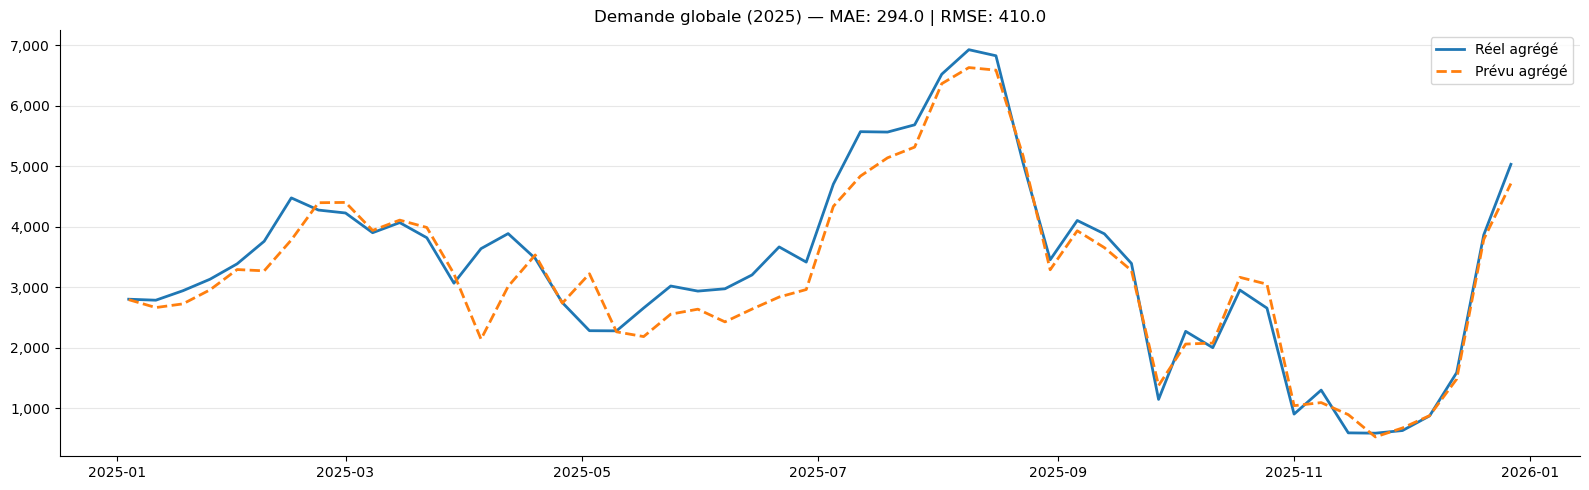

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Prédictions par segment (déjà entraîné)
preds_test = model.predict(X_test)

# Reconstruction propre du test avec DATE + VOLUME
test_plot = df_xgb.loc[test, ['DATE', TARGET]].copy()
test_plot.rename(columns={TARGET: 'VOLUME'}, inplace=True)
test_plot['PREDICTIONS'] = preds_test
test_plot['DATE'] = pd.to_datetime(test_plot['DATE'])

# --- Agrégation globale ---
macro = (
    test_plot
    .groupby('DATE', as_index=False)[['VOLUME', 'PREDICTIONS']]
    .sum()
    .sort_values('DATE')
)

# --- Métriques agrégées ---
mae_macro  = mean_absolute_error(macro['VOLUME'], macro['PREDICTIONS'])
rmse_macro = np.sqrt(mean_squared_error(macro['VOLUME'], macro['PREDICTIONS']))

print("=== Performance agrégée (tous établissements confondus) ===")
print(f"MAE  : {mae_macro:.2f}")
print(f"RMSE : {rmse_macro:.2f}")

# --- Plot global ---
plt.figure(figsize=(16,5))
plt.plot(macro['DATE'], macro['VOLUME'], linewidth=2, label='Réel agrégé')
plt.plot(macro['DATE'], macro['PREDICTIONS'], linewidth=2, linestyle='--', label='Prévu agrégé')
plt.title(f'Demande globale (2025) — MAE: {mae_macro:.1f} | RMSE: {rmse_macro:.1f}')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

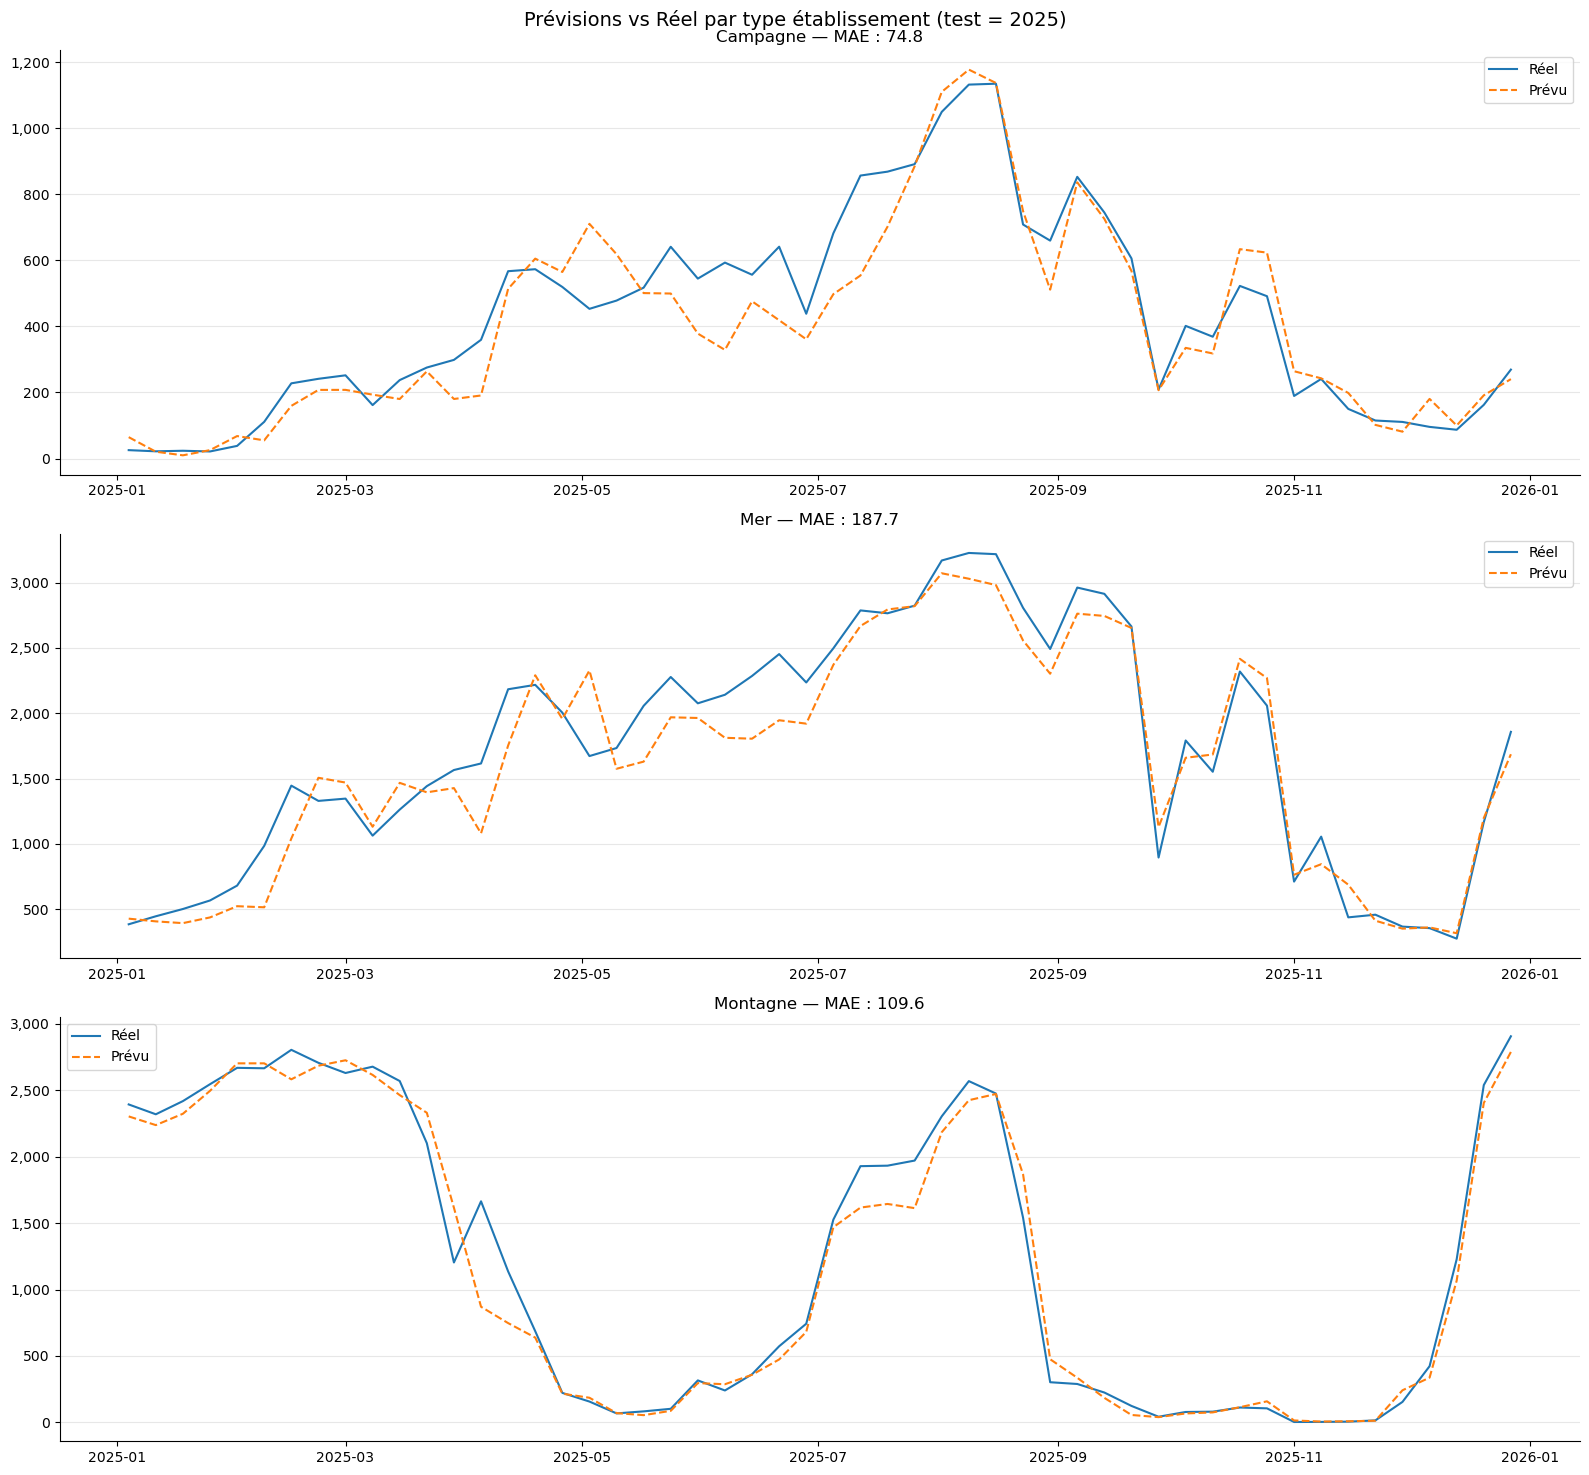

In [82]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.metrics import mean_absolute_error

# preds_test = model.predict(X_test)  # déjà calculé

# Reconstruire test_plot à partir de df_xgb + test_mask (pour garder DATE, VOLUME et VAR)
test_plot = df_xgb.loc[test, ['DATE', VAR, TARGET]].copy()
test_plot.rename(columns={TARGET: 'VOLUME'}, inplace=True)
test_plot['PREDICTIONS'] = preds_test
test_plot['DATE'] = pd.to_datetime(test_plot['DATE'])

types = test_plot[VAR].dropna().unique()

fig, axes = plt.subplots(len(types), 1, figsize=(16, 5*len(types)), sharex=False)

# Si un seul type, axes n'est pas itérable comme une liste
if len(types) == 1:
    axes = [axes]

for idx, t in enumerate(types):
    ax = axes[idx]
    subset = test_plot[test_plot[VAR] == t].sort_values('DATE')

    ax.plot(subset['DATE'], subset['VOLUME'],
            linewidth=1.5, label='Réel')
    ax.plot(subset['DATE'], subset['PREDICTIONS'],
            linewidth=1.5, linestyle='--', label='Prévu')

    mae_type = mean_absolute_error(subset['VOLUME'], subset['PREDICTIONS'])
    ax.set_title(f'{t} — MAE : {mae_type:.1f}', fontsize=12)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.suptitle('Prévisions vs Réel par type établissement (test = 2025)', fontsize=14)
plt.tight_layout()
plt.show()

#### **Prévisions avec Multi-VARS**

In [83]:
VARS = [ 'ID_TYPE_CHAMBRE', 'PARTENAIRE_SEG2', "ETABLISSEMENT_TYPE", "SAISON_SEJOUR"]
TARGET = "VOLUME"

In [84]:
data_temp = (
    data
    .groupby(VARS + ["SEMAINE_SEJOUR"])
    .agg(
        CA_N=('CA_N', 'sum'),
        VOLUME_N=('VOLUME_N', 'sum'),
        CA_N1DATE=('CA_N1FDS', 'sum'),
        VOLUME_N1DATE=('VOLUME_N1FDS', 'sum'),
        CA_N2DATE=('CA_N2FDS', 'sum'),
        VOLUME_N2DATE=('VOLUME_N2FDS', 'sum'),
        CA_N3DATE=('CA_N3FDS', 'sum'),
        VOLUME_N3DATE=('VOLUME_N3FDS', 'sum'),
    )
    .reset_index()
)

# Prix moyens
data_temp["PRIX_MOYEN_N"]  = data_temp["CA_N"]      / data_temp["VOLUME_N"]
data_temp["PRIX_MOYEN_N1"] = data_temp["CA_N1DATE"] / data_temp["VOLUME_N1DATE"]
data_temp["PRIX_MOYEN_N2"] = data_temp["CA_N2DATE"] / data_temp["VOLUME_N2DATE"]
data_temp["PRIX_MOYEN_N3"] = data_temp["CA_N3DATE"] / data_temp["VOLUME_N3DATE"]


# Dates et tri
data_temp["SEMAINE_SEJOUR"] = pd.to_datetime(data_temp["SEMAINE_SEJOUR"])
data_temp = data_temp.sort_values(["SEMAINE_SEJOUR"] + VARS).reset_index(drop=True)

# Variables ISO
iso = data_temp["SEMAINE_SEJOUR"].dt.isocalendar()
data_temp["WEEK_ISO"] = iso.week.astype(int)
data_temp["YEAR_N"] = iso.year.astype(int)

print("Nb modalités par variable:")
for v in VARS:
    print(v, ":", data_temp[v].nunique())
print("Shape data_temp:", data_temp.shape)

C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1922515525.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(VARS + ["SEMAINE_SEJOUR"])


Nb modalités par variable:
ID_TYPE_CHAMBRE : 530
PARTENAIRE_SEG2 : 29
ETABLISSEMENT_TYPE : 3
SAISON_SEJOUR : 2
Shape data_temp: (4887660, 19)


In [85]:
# Année N
df_n = data_temp[VARS + ["SEMAINE_SEJOUR", "WEEK_ISO", "YEAR_N", "VOLUME_N", "CA_N", "PRIX_MOYEN_N"]].copy()
df_n = df_n.rename(columns={
    "SEMAINE_SEJOUR": "DATE",
    "VOLUME_N": "VOLUME",
    "CA_N": "CA",
    "PRIX_MOYEN_N": "PRIX_MOYEN"
})
df_n["ANNEE"] = "N"
frames.append(df_n)

# Années N-1, N-2, N-3
for i, label in enumerate(["N1", "N2", "N3"], start=1):
    vol_col = f"VOLUME_{label}DATE"
    ca_col  = f"CA_{label}DATE"
    px_col  = f"PRIX_MOYEN_N{i}"

    df = data_temp[VARS + ["WEEK_ISO", "YEAR_N", vol_col, ca_col, px_col]].copy()
    df = df.rename(columns={
        vol_col: "VOLUME",
        ca_col: "CA",
        px_col: "PRIX_MOYEN"
    })
    df["ANNEE"] = f"N-{i}"
    df["DATE"] = df.apply(
        lambda row: pd.Timestamp(Week(int(row["YEAR_N"]) - i, int(row["WEEK_ISO"])).saturday()),
        axis=1
    )
    frames.append(df[VARS + ["DATE", "WEEK_ISO", "YEAR_N", "VOLUME", "CA", "PRIX_MOYEN", "ANNEE"]])


In [86]:
serie_continue = (
    pd.concat(frames)
    .sort_values(["DATE"] + VARS)
    .drop_duplicates(subset=VARS + ["DATE"], keep="first")
    .reset_index(drop=True)
)

In [87]:
## AJOUT DE LA BOOKING PACE
serie_continue = serie_continue.sort_values(VARS + ["DATE"]).reset_index(drop=True)

serie_continue["BOOKING_PACE"] = (
    serie_continue
    .groupby(VARS)["VOLUME"]
    .diff()   # V(t) - V(t-1)
)

C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1957543162.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(VARS)["VOLUME"]


In [88]:
serie_continue = serie_continue.merge(
    stock[["ID_TYPE_CHAMBRE", "STOCK_N"]],
    on="ID_TYPE_CHAMBRE",
    how="left"
)

serie_continue = serie_continue.rename(columns={"STOCK_N": "STOCK"})

In [89]:
df_xgb = serie_continue[["DATE"] + VARS + ["VOLUME", "PRIX_MOYEN", "STOCK"]].copy()
df_xgb = df_xgb.sort_values(["DATE"] + VARS).reset_index(drop=True)

# Features calendaires
df_xgb["WEEK_ISO"] = df_xgb["DATE"].dt.isocalendar().week.astype(int)
df_xgb["MONTH"] = df_xgb["DATE"].dt.month
df_xgb["YEAR"] = df_xgb["DATE"].dt.isocalendar().year.astype(int)

# Position dans la saison (ex: saison de S39 à S38)
semaines_ordre = list(range(39, 53)) + list(range(1, 39))
pos_map = {s: i+1 for i, s in enumerate(semaines_ordre)}
df_xgb["POSITION_SAISON"] = df_xgb["WEEK_ISO"].map(pos_map)

df_xgb['PRIX_MOYEN'] = df_xgb['PRIX_MOYEN'].replace(-np.inf, 0)


In [90]:
for lag in [1,2, 3, 4, 5, 7, 9, 15, 26, 52]:
    df_xgb[f"lag_{lag}"] = df_xgb.groupby(VARS)["VOLUME"].shift(lag)

# Suppression des NaN dus aux lags
df_xgb = df_xgb.dropna().reset_index(drop=True)

print("Shape df_xgb après lags:", df_xgb.shape)


C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1448106764.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_xgb[f"lag_{lag}"] = df_xgb.groupby(VARS)["VOLUME"].shift(lag)
C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1448106764.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_xgb[f"lag_{lag}"] = df_xgb.groupby(VARS)["VOLUME"].shift(lag)
C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1448106764.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future 

Shape df_xgb après lags: (202477, 22)


In [91]:
## TARGET ENCODING

for col in VARS:
    means = df_xgb.groupby(col)["VOLUME"].mean()
    df_xgb[col + "_ENC"] = df_xgb[col].map(means)

enc_cols = [f"{col}_ENC" for col in VARS]

df_xgb[enc_cols] = df_xgb[enc_cols].astype(float)

C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1736205425.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = df_xgb.groupby(col)["VOLUME"].mean()
C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1736205425.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = df_xgb.groupby(col)["VOLUME"].mean()
C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1736205425.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean

In [92]:
FEATURES = [
    "WEEK_ISO", "MONTH", "POSITION_SAISON", "PRIX_MOYEN", 
] + [f"{col}_ENC" for col in VARS] + [
    "lag_1",'lag_2', 'lag_3', "lag_4", "lag_5", "lag_7", "lag_9", "lag_15", "lag_26", "lag_52"
]

TARGET = "VOLUME"

print("FEATURES:")
print(FEATURES)

FEATURES:
['WEEK_ISO', 'MONTH', 'POSITION_SAISON', 'PRIX_MOYEN', 'ID_TYPE_CHAMBRE_ENC', 'PARTENAIRE_SEG2_ENC', 'ETABLISSEMENT_TYPE_ENC', 'SAISON_SEJOUR_ENC', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_7', 'lag_9', 'lag_15', 'lag_26', 'lag_52']


In [93]:
df_xgb['PRIX_MOYEN'] = (
    df_xgb['PRIX_MOYEN']
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

In [94]:
train_years = [2023, 2024]
test_year = 2025

train = df_xgb['YEAR'].isin(train_years)
test  = df_xgb['YEAR'].eq(test_year)

X_train = df_xgb.loc[train, FEATURES]
y_train = df_xgb.loc[train, TARGET]

X_test  = df_xgb.loc[test, FEATURES]
y_test  = df_xgb.loc[test, TARGET]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Années train:", df_xgb.loc[train, 'YEAR'].value_counts().sort_index().to_dict())
print("Année test:", df_xgb.loc[test, 'YEAR'].value_counts().sort_index().to_dict())


Train: (87626, 18) Test: (81224, 18)
Années train: {2023: 12321, 2024: 75305}
Année test: {2025: 81224}


In [95]:
model = XGBRegressor(
    n_estimators=700,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
)

model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.85, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=700,
             n_jobs=-1, num_parallel_tree=None, ...)

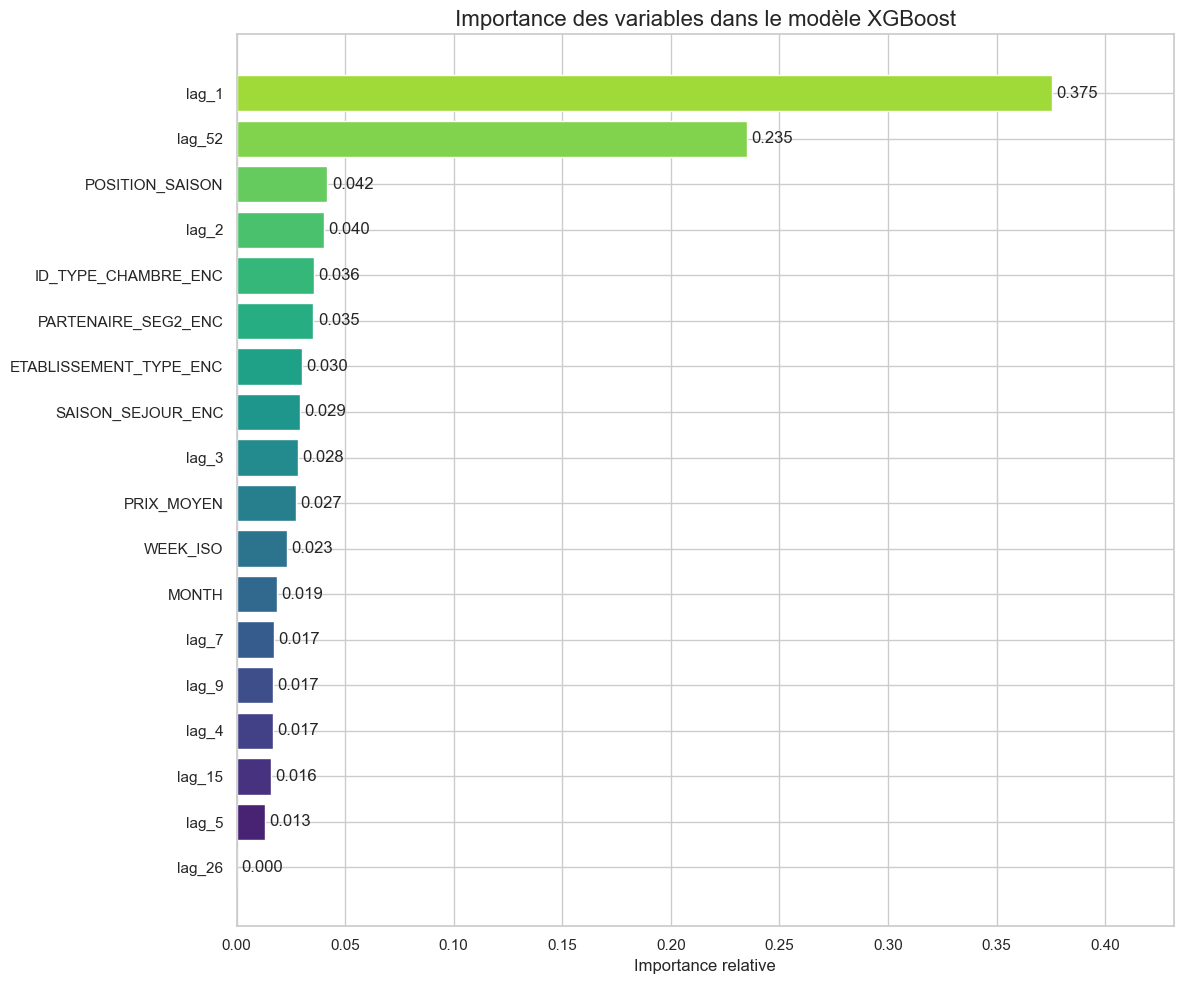

In [96]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Création du dataframe
importance_df = pd.DataFrame({
    "Variable": FEATURES,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values("Importance", ascending=False)

top_n = 20
plot_df = importance_df.head(top_n).sort_values("Importance")

# Style graphique
sns.set(style="whitegrid")

plt.figure(figsize=(12,10))

bars = plt.barh(
    plot_df["Variable"],
    plot_df["Importance"],
    color=sns.color_palette("viridis", top_n)
)

# Ajouter les valeurs à côté des barres
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.002,
        bar.get_y() + bar.get_height()/2,
        f"{width:.3f}",
        va='center'
    )

plt.title("Importance des variables dans le modèle XGBoost", fontsize=16)
plt.xlabel("Importance relative", fontsize=12)
plt.ylabel("")
plt.xlim(0, plot_df["Importance"].max()*1.15)

plt.tight_layout()
plt.show()

In [97]:
print("Dimensions de X_test :", X_test.shape)
print("Dimensions de y_test :", y_test.shape)
print("Nombre de prédictions :", len(preds_test))
print("Dimensions de df_xgb :", df_xgb.shape)
print("Nombre d'indices test :", len(test))

print("\nType de preds_test :", type(preds_test))
print("Dimensions de preds_test :", np.shape(preds_test))

Dimensions de X_test : (81224, 18)
Dimensions de y_test : (81224,)
Nombre de prédictions : 156
Dimensions de df_xgb : (202477, 26)
Nombre d'indices test : 202477

Type de preds_test : <class 'numpy.ndarray'>
Dimensions de preds_test : (156,)


In [98]:
print("Index X_test :", X_test.index[:10])
print("Index y_test :", y_test.index[:10])
print("Index test :", test[:10])

Index X_test : Index([87626, 87627, 87628, 87629, 87630, 87631, 87632, 87633, 87634, 87635], dtype='int64')
Index y_test : Index([87626, 87627, 87628, 87629, 87630, 87631, 87632, 87633, 87634, 87635], dtype='int64')
Index test : 0    False
1    False
2    False
3    False
4    False
5    False
6    False
7    False
8    False
9    False
Name: YEAR, dtype: bool


In [99]:
preds_test = model.predict(X_test)

print("Nombre de prédictions :", len(preds_test))
print("Nombre d'observations :", len(X_test))

Nombre de prédictions : 81224
Nombre d'observations : 81224


In [100]:
df_eval = X_test.copy()

df_eval["REAL"] = y_test.values
df_eval["PRED"] = preds_test

df_eval["DATE"] = df_xgb.loc[X_test.index, "DATE"].values

weekly = (
    df_eval
    .groupby("DATE")[["REAL", "PRED"]]
    .sum()
    .reset_index()
)

weekly.head()

,DATE,REAL,PRED
0,2025-01-04,2802.855938,2874.326904
1,2025-01-11,2786.427657,2789.301514
2,2025-01-18,2943.141741,2949.932129
3,2025-01-25,3133.427505,3076.100830
4,2025-02-01,3387.569866,3372.472168


In [101]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = weekly["REAL"]
y_pred = weekly["PRED"]

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

wape = (
    np.sum(np.abs(y_true - y_pred))
    / np.sum(np.abs(y_true))
) * 100

bias = np.sum(y_pred - y_true) / np.sum(y_true) * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"WAPE : {wape:.2f}%")
print(f"Biais : {bias:.2f}%")

MAE  : 179.58
RMSE : 267.67
MAPE : 6.43%
WAPE : 5.34%
Biais : -0.11%


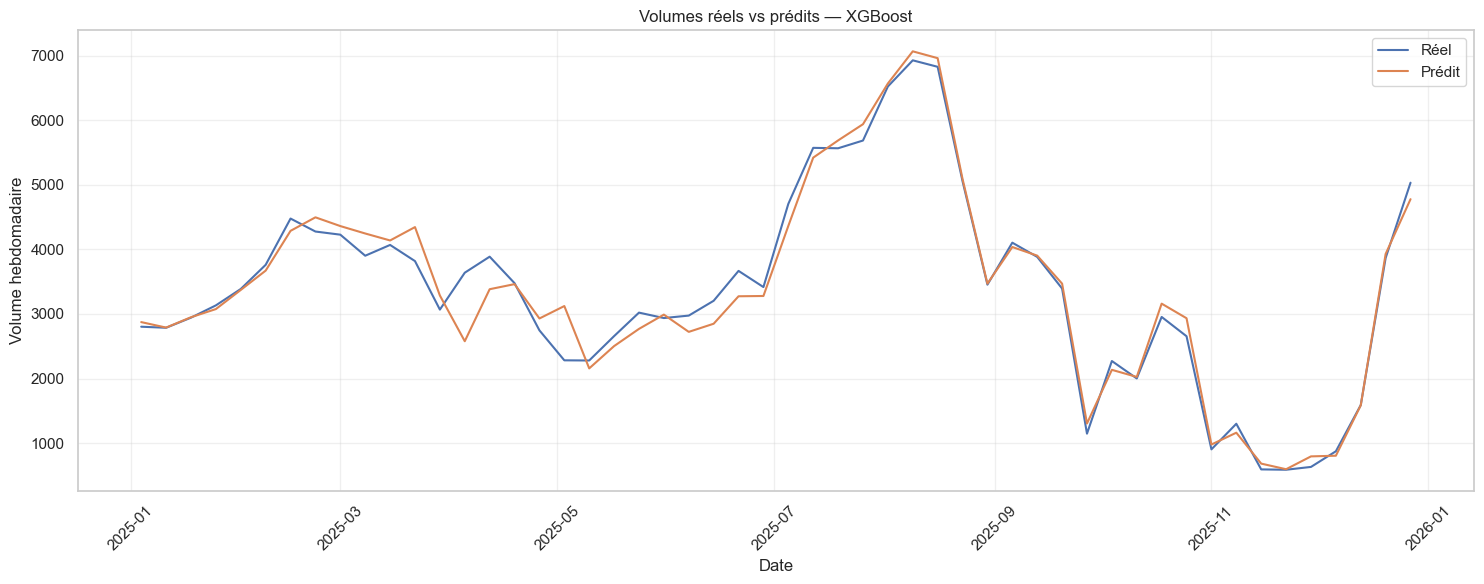

In [102]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(weekly["DATE"], weekly["REAL"], label="Réel")
plt.plot(weekly["DATE"], weekly["PRED"], label="Prédit")

plt.title("Volumes réels vs prédits — XGBoost")
plt.xlabel("Date")
plt.ylabel("Volume hebdomadaire")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

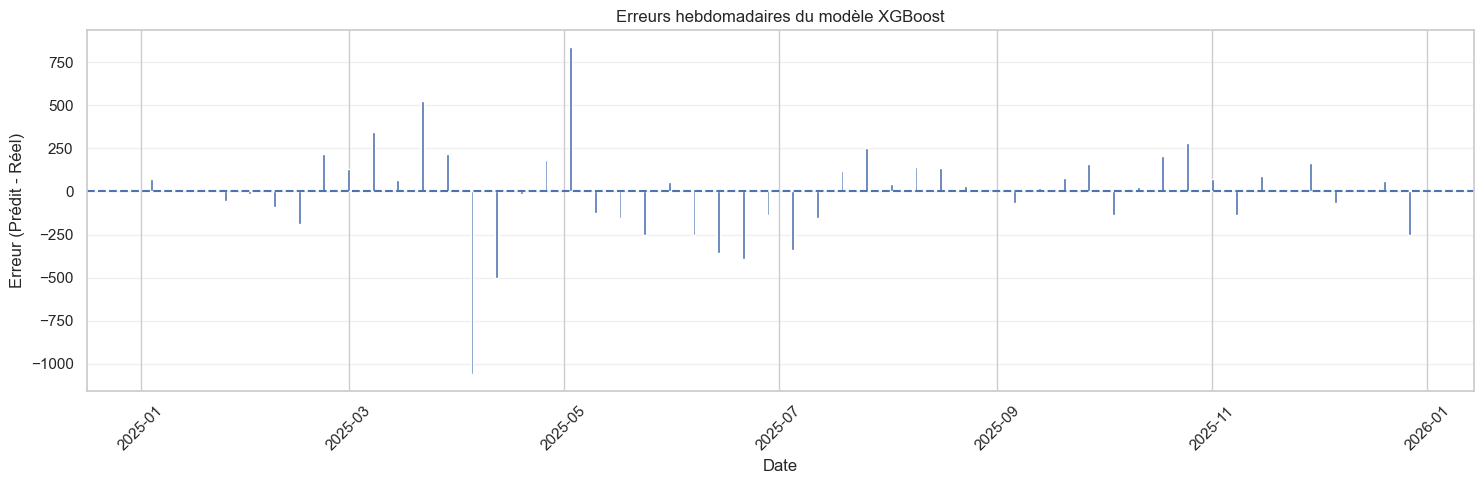

In [103]:
weekly["ERROR"] = weekly["PRED"] - weekly["REAL"]

plt.figure(figsize=(15, 5))

plt.bar(weekly["DATE"], weekly["ERROR"])
plt.axhline(0, linestyle="--")

plt.title("Erreurs hebdomadaires du modèle XGBoost")
plt.xlabel("Date")
plt.ylabel("Erreur (Prédit - Réel)")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.metrics import mean_absolute_error, mean_squared_error


preds_test = model.predict(X_test)

cols_keep = ['DATE', TARGET] + VARS
test_plot = df_xgb.loc[test, cols_keep].copy()
test_plot.rename(columns={TARGET: 'VOLUME'}, inplace=True)
test_plot['PREDICTIONS'] = preds_test
test_plot['DATE'] = pd.to_datetime(test_plot['DATE'])

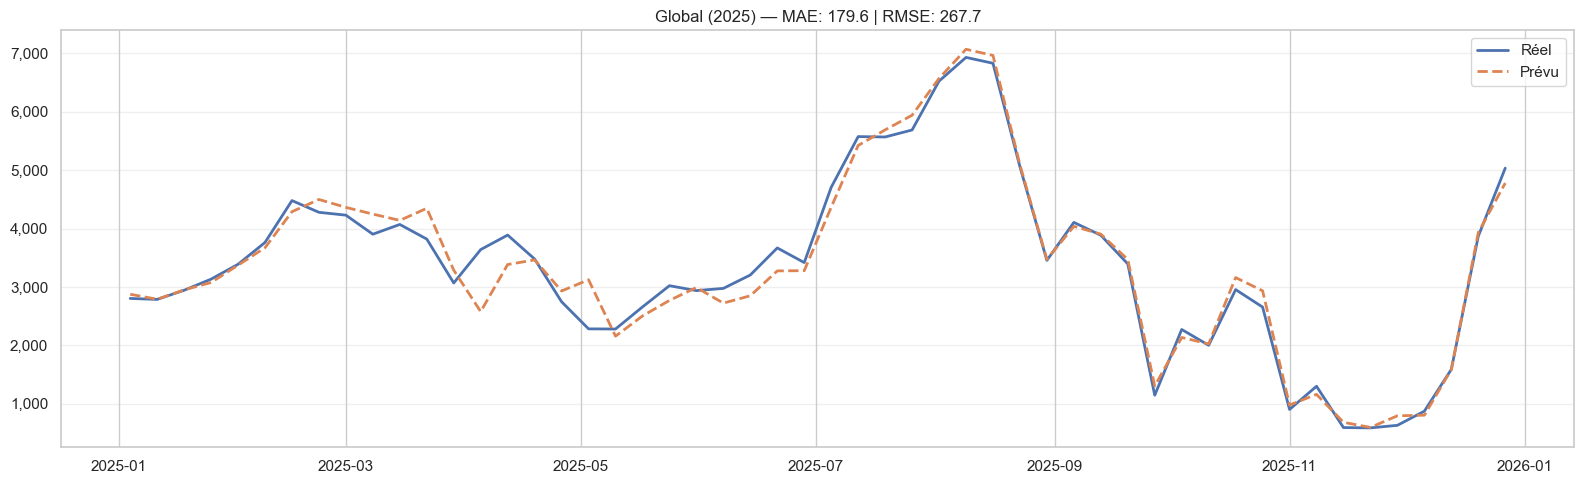

In [105]:
macro = (
    test_plot
    .groupby('DATE', as_index=False)[['VOLUME', 'PREDICTIONS']]
    .sum()
    .sort_values('DATE')
)

mae  = mean_absolute_error(macro['VOLUME'], macro['PREDICTIONS'])
rmse = np.sqrt(mean_squared_error(macro['VOLUME'], macro['PREDICTIONS']))

plt.figure(figsize=(16,5))
plt.plot(macro['DATE'], macro['VOLUME'], linewidth=2, label='Réel')
plt.plot(macro['DATE'], macro['PREDICTIONS'], linewidth=2, linestyle='--', label='Prévu')
plt.title(f"Global (2025) — MAE: {mae:.1f} | RMSE: {rmse:.1f}")
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

In [106]:

# ============================================================
# MAE / RMSE — par segment, sous-segment et demande globale reconstruite
# ============================================================
from itertools import combinations
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

records = []

# ── 1. Niveau GLOBAL ─────────────────────────────────────────
macro = (
    test_plot
    .groupby('DATE')[['VOLUME', 'PREDICTIONS']]
    .sum()
)
records.append({
    "Niveau":      "Global",
    "Segment":     "—",
    "Modalité":    "Toutes",
    "MAE":         mean_absolute_error(macro['VOLUME'], macro['PREDICTIONS']),
    "RMSE":        np.sqrt(mean_squared_error(macro['VOLUME'], macro['PREDICTIONS'])),
    "Volume_réel": macro['VOLUME'].sum(),
})

# ── 2. Niveau par variable de segmentation (1 var) ───────────
for var in VARS:
    series = (
        test_plot
        .groupby(['DATE', var])[['VOLUME', 'PREDICTIONS']]
        .sum()
        .reset_index()
    )
    for modalite in series[var].unique():
        sub = series[series[var] == modalite].sort_values('DATE')
        records.append({
            "Niveau":      "Segment (1 var)",
            "Segment":     var,
            "Modalité":    str(modalite),
            "MAE":         mean_absolute_error(sub['VOLUME'], sub['PREDICTIONS']),
            "RMSE":        np.sqrt(mean_squared_error(sub['VOLUME'], sub['PREDICTIONS'])),
            "Volume_réel": sub['VOLUME'].sum(),
        })

# ── 3. Niveau par paire de variables (sous-segment) ──────────
for var1, var2 in combinations(VARS, 2):
    series = (
        test_plot
        .groupby(['DATE', var1, var2])[['VOLUME', 'PREDICTIONS']]
        .sum()
        .reset_index()
    )
    combos = series[[var1, var2]].drop_duplicates()
    for _, row in combos.iterrows():
        mask = (series[var1] == row[var1]) & (series[var2] == row[var2])
        sub = series[mask].sort_values('DATE')
        records.append({
            "Niveau":      f"Sous-segment ({var1} × {var2})",
            "Segment":     f"{var1} × {var2}",
            "Modalité":    f"{row[var1]} | {row[var2]}",
            "MAE":         mean_absolute_error(sub['VOLUME'], sub['PREDICTIONS']),
            "RMSE":        np.sqrt(mean_squared_error(sub['VOLUME'], sub['PREDICTIONS'])),
            "Volume_réel": sub['VOLUME'].sum(),
        })

metrics_df = pd.DataFrame(records)

# ── Résumé : MAE et RMSE moyens pondérés par volume, par niveau ─
summary = (
    metrics_df
    .assign(
        poids = metrics_df['Volume_réel'],
        MAE_pond  = metrics_df['MAE']  * metrics_df['Volume_réel'],
        RMSE_pond = metrics_df['RMSE'] * metrics_df['Volume_réel'],
    )
    .groupby('Niveau')
    .apply(lambda g: pd.Series({
        "MAE_moyen_pondéré":  g['MAE_pond'].sum()  / g['poids'].sum(),
        "RMSE_moyen_pondéré": g['RMSE_pond'].sum() / g['poids'].sum(),
        "MAE_moyen_simple":   g['MAE'].mean(),
        "RMSE_moyen_simple":  g['RMSE'].mean(),
        "Nb_séries":          len(g),
    }), include_groups=False)
    .reset_index()
)

print("=" * 65)
print("RÉSUMÉ — MAE / RMSE par niveau d'agrégation")
print("=" * 65)
print(summary.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
print()

# ── Table détaillée par segment (1 var) ──────────────────────
print("=" * 65)
print("DÉTAIL — Segments (1 variable)")
print("=" * 65)
detail_1var = (
    metrics_df[metrics_df['Niveau'] == 'Segment (1 var)']
    [['Segment', 'Modalité', 'MAE', 'RMSE', 'Volume_réel']]
    .sort_values(['Segment', 'MAE'], ascending=[True, False])
)
print(detail_1var.to_string(index=False, float_format=lambda x: f"{x:.2f}"))


C:\Users\HP\AppData\Local\Temp\ipykernel_19476\190110561.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['DATE', var])[['VOLUME', 'PREDICTIONS']]
C:\Users\HP\AppData\Local\Temp\ipykernel_19476\190110561.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['DATE', var])[['VOLUME', 'PREDICTIONS']]
C:\Users\HP\AppData\Local\Temp\ipykernel_19476\190110561.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this war

RÉSUMÉ — MAE / RMSE par niveau d'agrégation
                                             Niveau  MAE_moyen_pondéré  RMSE_moyen_pondéré  MAE_moyen_simple  RMSE_moyen_simple  Nb_séries
                                             Global             179.58              267.67            179.58             267.67       1.00
                                    Segment (1 var)              54.69               94.32              3.37               4.87     518.00
  Sous-segment (ETABLISSEMENT_TYPE × SAISON_SEJOUR)              48.22               99.06             36.19              75.84       6.00
Sous-segment (ID_TYPE_CHAMBRE × ETABLISSEMENT_TYPE)               3.09                4.56              0.42               0.66    1452.00
   Sous-segment (ID_TYPE_CHAMBRE × PARTENAIRE_SEG2)               0.95                1.65              0.10               0.22   14036.00
     Sous-segment (ID_TYPE_CHAMBRE × SAISON_SEJOUR)               1.72                3.37              0.63              

C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1026442121.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['DATE', GROUP_VAR], as_index=False)[['VOLUME','PREDICTIONS']]


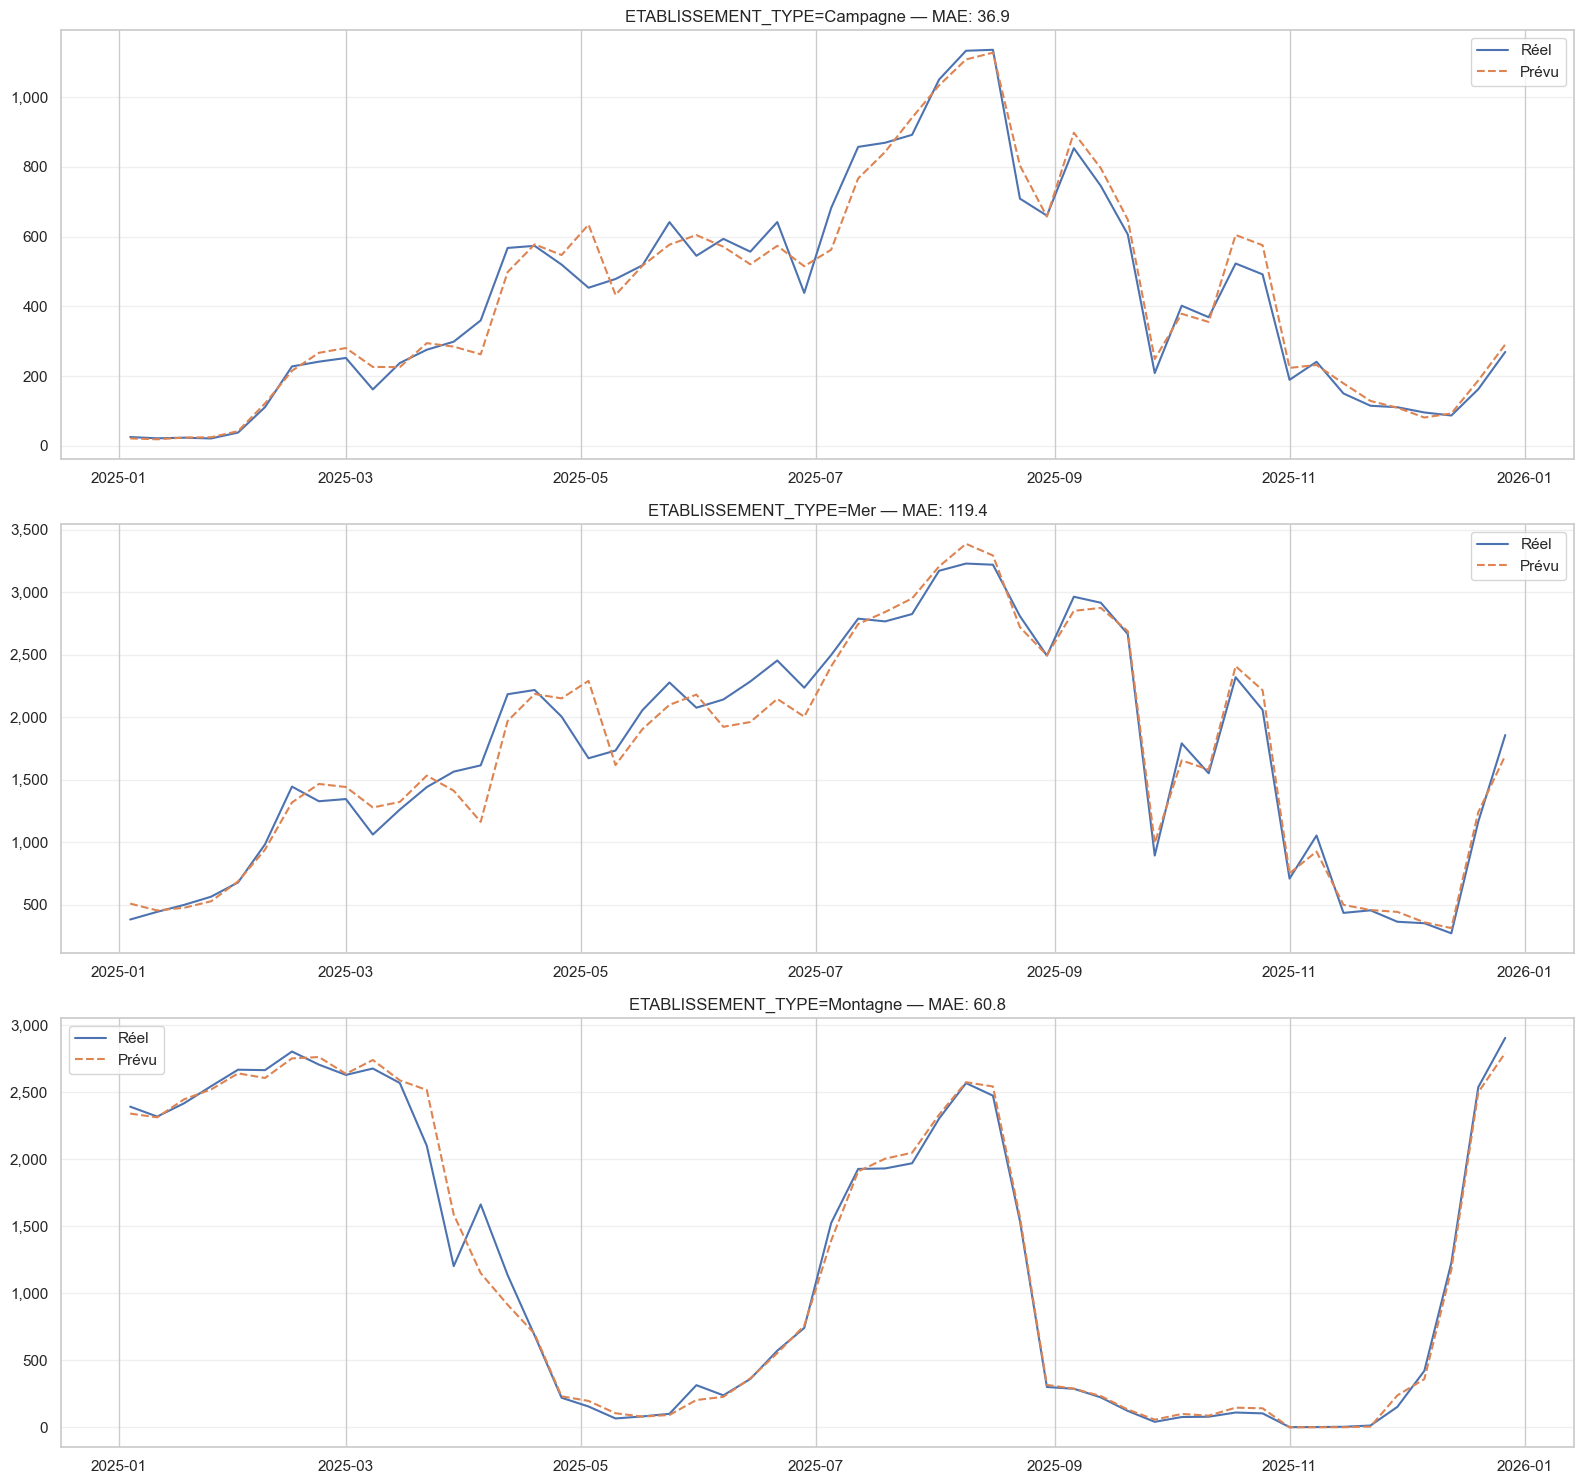

In [107]:
GROUP_VAR = VARS[2]   # ou 'ETABLISSEMENT_TYPE' par ex

series = (
    test_plot
    .groupby(['DATE', GROUP_VAR], as_index=False)[['VOLUME','PREDICTIONS']]
    .sum()
    .sort_values('DATE')
)

values = series[GROUP_VAR].dropna().unique()
fig, axes = plt.subplots(len(values), 1, figsize=(16, 5*len(values)), sharex=False)

if len(values) == 1:
    axes = [axes]

for i, v in enumerate(values):
    ax = axes[i]
    sub = series[series[GROUP_VAR] == v].sort_values('DATE')
    ax.plot(sub['DATE'], sub['VOLUME'], linewidth=1.5, label='Réel')
    ax.plot(sub['DATE'], sub['PREDICTIONS'], linewidth=1.5, linestyle='--', label='Prévu')
    mae_v = mean_absolute_error(sub['VOLUME'], sub['PREDICTIONS'])
    ax.set_title(f"{GROUP_VAR}={v} — MAE: {mae_v:.1f}")
    ax.grid(axis='y', alpha=0.3)
    ax.legend()
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1525861021.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['DATE'] + GROUP_VARS, as_index=False)[['VOLUME','PREDICTIONS']]
C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1525861021.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(GROUP_VARS, as_index=False)['VOLUME']


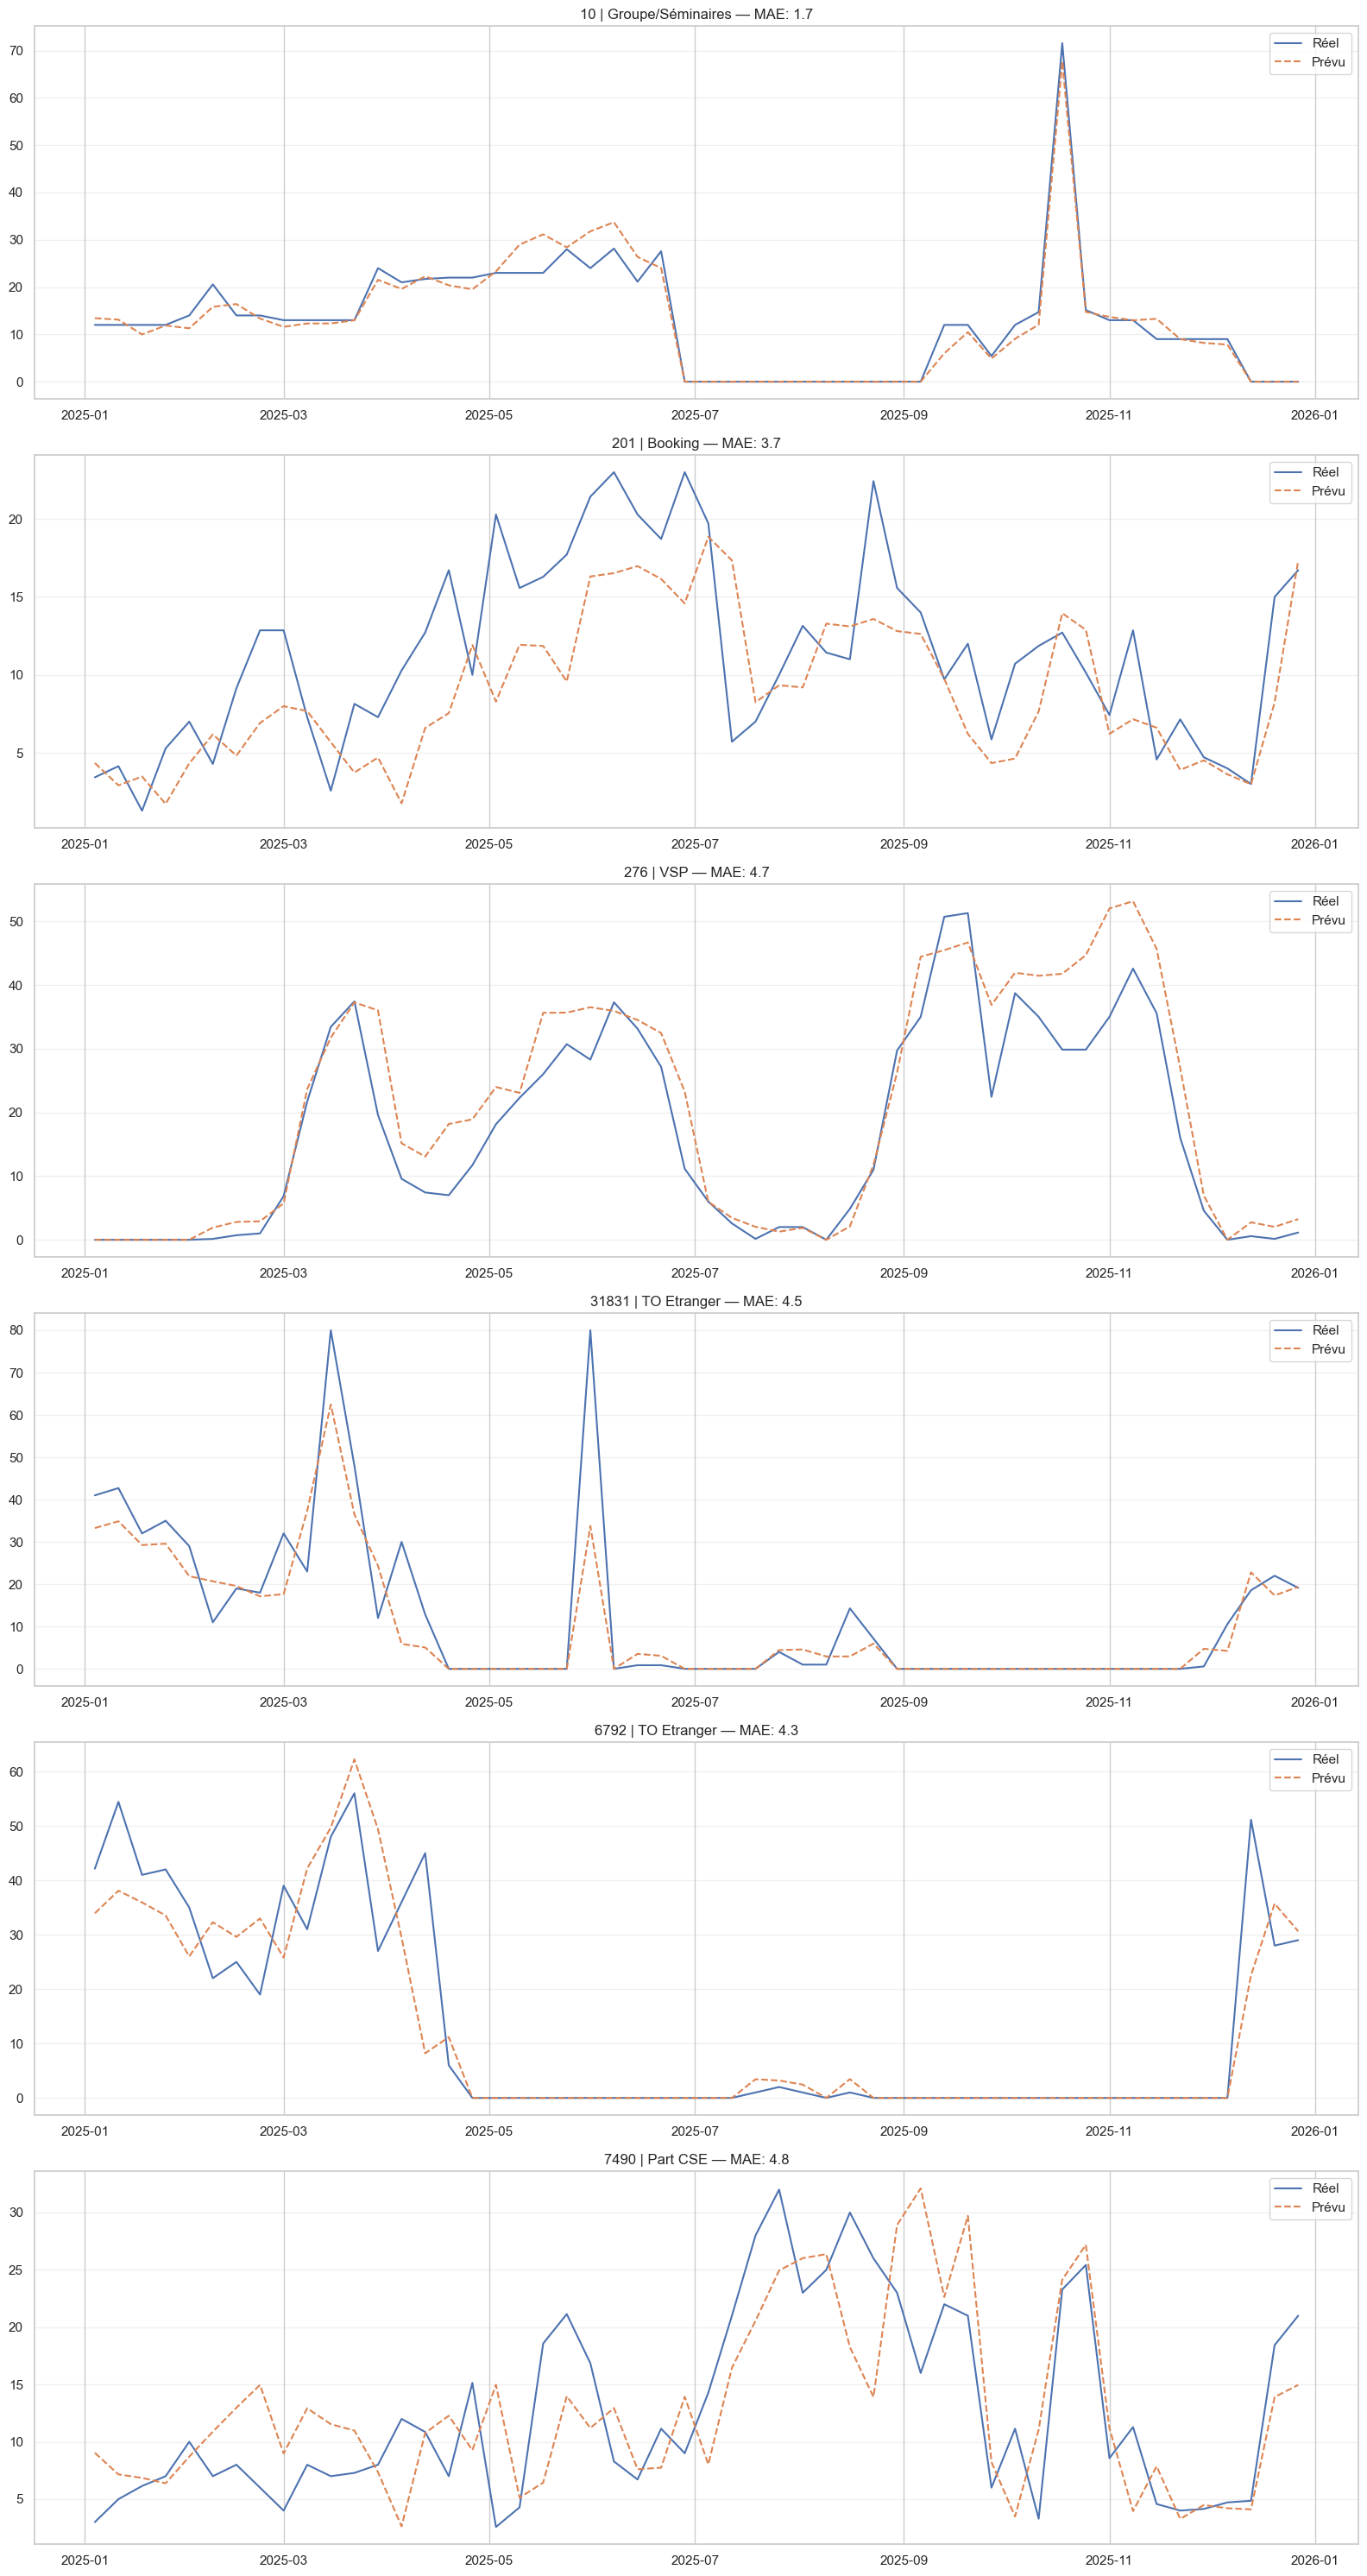

In [108]:
#VARS = [ 'ID_TYPE_CHAMBRE', 'PARTENAIRE_SEG2', "ETABLISSEMENT_TYPE", "SAISON_SEJOUR"]
GROUP_VARS = VARS[0:2]  # ex: ['ETABLISSEMENT_TYPE','CANAL_VENTE']
TOP_K = 6               # nombre de combos à afficher

series2 = (
    test_plot
    .groupby(['DATE'] + GROUP_VARS, as_index=False)[['VOLUME','PREDICTIONS']]
    .sum()
)

# Top K combos par volume total réel
top_combos = (
    series2
    .groupby(GROUP_VARS, as_index=False)['VOLUME']
    .sum()
    .sort_values('VOLUME', ascending=False)
    .head(TOP_K)
)

series2 = series2.merge(top_combos[GROUP_VARS], on=GROUP_VARS, how='inner')
series2 = series2.sort_values('DATE')

# Label lisible pour chaque combo
series2['COMBO'] = series2[GROUP_VARS].astype(str).agg(' | '.join, axis=1)

combos = series2['COMBO'].unique()
fig, axes = plt.subplots(len(combos), 1, figsize=(16, 5*len(combos)), sharex=False)
if len(combos) == 1:
    axes = [axes]

for i, c in enumerate(combos):
    ax = axes[i]
    sub = series2[series2['COMBO'] == c].sort_values('DATE')
    ax.plot(sub['DATE'], sub['VOLUME'], linewidth=1.5, label='Réel')
    ax.plot(sub['DATE'], sub['PREDICTIONS'], linewidth=1.5, linestyle='--', label='Prévu')
    mae_c = mean_absolute_error(sub['VOLUME'], sub['PREDICTIONS'])
    ax.set_title(f"{c} — MAE: {mae_c:.1f}")
    ax.grid(axis='y', alpha=0.3)
    ax.legend()
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.tight_layout()
plt.show()

In [109]:
import xgboost as xgb
import pandas as pd
import numpy as np

# création du DMatrix
dtest = xgb.DMatrix(X_test)

# contributions des variables (SHAP)
shap_values = model.get_booster().predict(dtest, pred_contribs=True)

In [110]:
shap_df = pd.DataFrame(
    shap_values[:, :-1],
    columns=FEATURES,
    index=X_test.index
)

In [111]:
shap_importance = pd.DataFrame({
    "Variable": FEATURES,
    "Mean_ABS_SHAP": np.abs(shap_df).mean()
}).sort_values("Mean_ABS_SHAP", ascending=False)

C:\Users\HP\AppData\Local\Temp\ipykernel_19476\1369271677.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


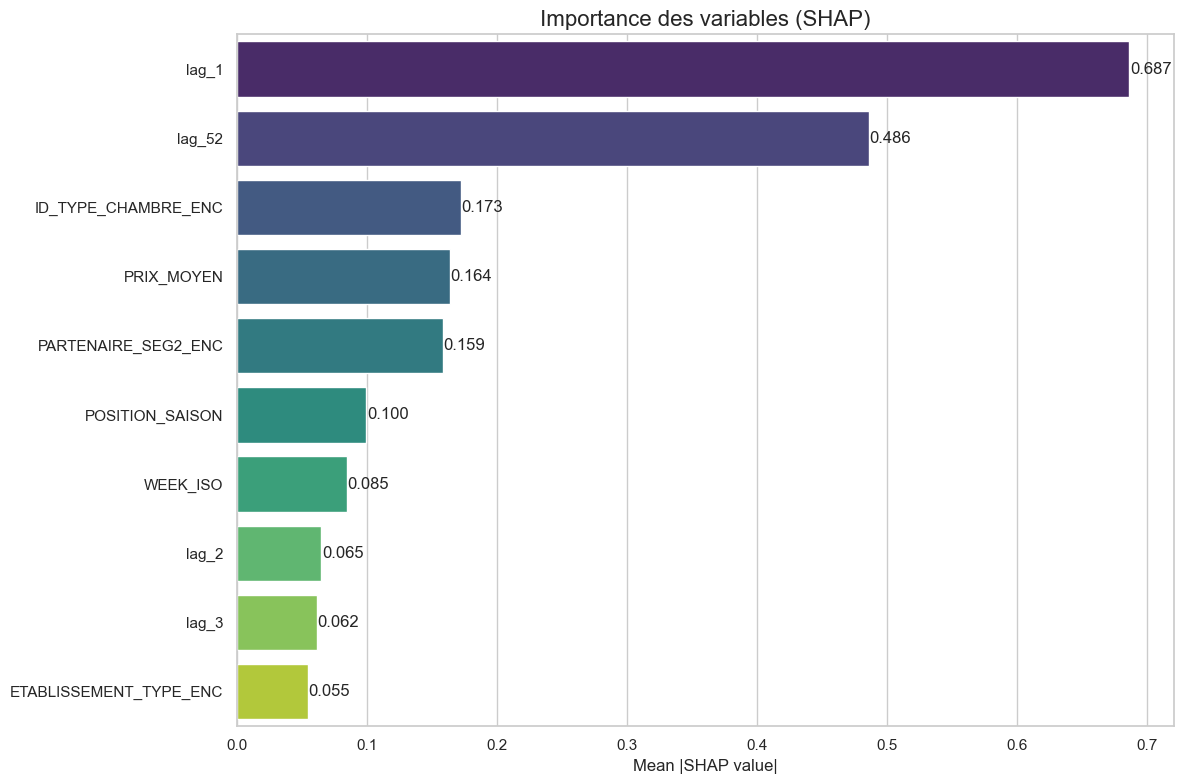

In [112]:
import matplotlib.pyplot as plt
import seaborn as sns

top_n = 10
plot_df = shap_importance.head(top_n)  # déjà trié du plus grand au plus petit

plt.figure(figsize=(12,8))

ax = sns.barplot(
    x="Mean_ABS_SHAP",
    y="Variable",
    data=plot_df,
    palette="viridis"
)

# ajouter la valeur au bout de chaque barre
for i, v in enumerate(plot_df["Mean_ABS_SHAP"]):
    ax.text(v + 0.0005, i, f"{v:.3f}", va='center')

plt.title("Importance des variables (SHAP)", fontsize=16)
plt.xlabel("Mean |SHAP value|")
plt.ylabel("")

plt.tight_layout()
plt.show()

In [117]:
# ═══════════════════════════════════════════════════════════════════════════
#  DISAGGREGATED DEMAND FORECASTING MODEL — ODALYS VACANCES
#  Static XGBoost — Micro Level (ETABLISSEMENT_TYPE × PARTENAIRE_SEG2)
# ═══════════════════════════════════════════════════════════════════════════

# ───────────────────────────────────────────────────────────────────────────
# BLOCK 1 — AGGREGATION AT MICRO LEVEL
# ───────────────────────────────────────────────────────────────────────────

DIMS = ['ETABLISSEMENT_TYPE', 'PARTENAIRE_SEG2', 'ID_TYPE_CHAMBRE']

data_micro = (
    data
    .groupby(DIMS + ['SEMAINE_SEJOUR'])
    .agg(
        VOLUME_N  = ('VOLUME_N',    'sum'),
        VOLUME_N1 = ('VOLUME_N1FDS','sum'),
        VOLUME_N2 = ('VOLUME_N2FDS','sum'),
        VOLUME_N3 = ('VOLUME_N3FDS','sum'),
        CA_N      = ('CA_N',        'sum'),
        CA_N1     = ('CA_N1FDS',    'sum'),
        CA_N2     = ('CA_N2FDS',    'sum'),
        CA_N3     = ('CA_N3FDS',    'sum'),
    )
    .reset_index()
)

# Prix moyens
for s, v, c in [('N', 'VOLUME_N','CA_N'),
                ('N1','VOLUME_N1','CA_N1'),
                ('N2','VOLUME_N2','CA_N2'),
                ('N3','VOLUME_N3','CA_N3')]:
    data_micro[f'AVG_PRICE_{s}'] = (
        data_micro[c] / data_micro[v]
    ).replace([np.inf, -np.inf], np.nan).fillna(0)

data_micro['SEMAINE_SEJOUR'] = pd.to_datetime(data_micro['SEMAINE_SEJOUR'])
data_micro = data_micro.sort_values(
    DIMS + ['SEMAINE_SEJOUR']).reset_index(drop=True)

iso_ = data_micro['SEMAINE_SEJOUR'].dt.isocalendar()
data_micro['WEEK_ISO'] = iso_.week.astype(int)
data_micro['YEAR_N']   = iso_.year.astype(int)

# Forcer str sur DIMS
for col in DIMS:
    data_micro[col] = data_micro[col].astype(str)

# ── Filtre combinaisons actives volume >= 10 ──────────────────────────────
vol_by_combo = data_micro.groupby(DIMS)['VOLUME_N'].sum().reset_index()
active_combos = vol_by_combo[vol_by_combo['VOLUME_N'] >= 10][DIMS]
data_micro = data_micro.merge(active_combos, on=DIMS, how='inner')

print(f"✓ Active combinations (volume ≥ 10) : "
      f"{data_micro[DIMS].drop_duplicates().shape[0]}")
print(f"  Shape data_micro : {data_micro.shape}")

# ───────────────────────────────────────────────────────────────────────────
# BLOCK 2 — LONG FORMAT TIME SERIES RECONSTRUCTION
# ───────────────────────────────────────────────────────────────────────────

frames_micro = []

# Season N
df_n = data_micro[
    DIMS + ['SEMAINE_SEJOUR','WEEK_ISO','YEAR_N',
            'VOLUME_N','CA_N','AVG_PRICE_N']
].copy()
df_n.columns = DIMS + ['DATE','WEEK_ISO','YEAR_N','VOLUME','CA','AVG_PRICE']
df_n['SEASON'] = 'N'
frames_micro.append(df_n)

# Seasons N-1, N-2, N-3
for i, label in enumerate(['N1','N2','N3'], start=1):
    df = data_micro[
        DIMS + ['WEEK_ISO','YEAR_N',
                f'VOLUME_{label}',f'CA_{label}',f'AVG_PRICE_{label}']
    ].copy()
    df.columns = DIMS + ['WEEK_ISO','YEAR_N','VOLUME','CA','AVG_PRICE']
    df['SEASON'] = f'N-{i}'
    df['DATE'] = df.apply(
        lambda row: pd.Timestamp(
            Week(int(row['YEAR_N'])-i, int(row['WEEK_ISO'])).saturday()
        ), axis=1
    )
    frames_micro.append(
        df[DIMS + ['DATE','WEEK_ISO','YEAR_N',
                   'VOLUME','CA','AVG_PRICE','SEASON']]
    )

serie_micro = (
    pd.concat(frames_micro)
    .sort_values(DIMS + ['DATE'])
    .drop_duplicates(subset=DIMS + ['DATE'], keep='first')
    .reset_index(drop=True)
)

print(f"\n✓ Micro time series reconstructed : {len(serie_micro)} observations")
print(serie_micro.groupby(
    serie_micro['DATE'].dt.year)['VOLUME'].agg(['count','sum']).round(0))

# ───────────────────────────────────────────────────────────────────────────
# BLOCK 3 — FEATURE ENGINEERING
# ───────────────────────────────────────────────────────────────────────────

# ───────────────────────────────────────────────────────────────────────────
# BLOCK 3 — FEATURE ENGINEERING
# ───────────────────────────────────────────────────────────────────────────

df_micro = serie_micro[
    DIMS + ['DATE', 'VOLUME', 'AVG_PRICE']
].copy()

df_micro['DATE'] = pd.to_datetime(df_micro['DATE'])

# Temporal features
iso_m = df_micro['DATE'].dt.isocalendar()

df_micro['WEEK_ISO'] = iso_m.week.astype(int)
df_micro['MONTH'] = df_micro['DATE'].dt.month
df_micro['YEAR'] = iso_m.year.astype(int)

df_micro['WINTER_SEASON'] = df_micro['MONTH'].isin(
    [10, 11, 12, 1, 2, 3]
).astype(int)

# Position dans la saison touristique
season_order = list(range(39, 53)) + list(range(1, 39))

pos_map_micro = {
    s: i + 1 for i, s in enumerate(season_order)
}

df_micro['SEASON_POSITION'] = (
    df_micro['WEEK_ISO'].map(pos_map_micro)
)

# Saison fiscale
def fiscal_season_micro(row):
    w, y = row['WEEK_ISO'], row['YEAR']
    return f"{y}-{y+1}" if w >= 39 else f"{y-1}-{y}"

df_micro['FISCAL_SEASON'] = df_micro.apply(
    fiscal_season_micro, axis=1
)

# Lags calculés PAR combinaison
LAG_LIST = [1, 2, 4]

for lag in LAG_LIST:
    df_micro[f'lag_{lag}'] = (
        df_micro.groupby(DIMS)['VOLUME'].shift(lag)
    )

# Booking pace PAR combinaison
df_micro['BOOKING_PACE'] = (
    df_micro.groupby(DIMS)['VOLUME'].diff(1)
)

# Nettoyage
df_micro = df_micro.dropna().reset_index(drop=True)

df_micro = df_micro[
    df_micro['FISCAL_SEASON'] != '2026-2027'
].reset_index(drop=True)

# Forcer str sur DIMS
for col in DIMS:
    df_micro[col] = df_micro[col].astype(str)

print("\n✓ Features engineered")

print("\nFiscal seasons available :")

print(
    df_micro.groupby('FISCAL_SEASON')['VOLUME']
    .agg(['count', 'sum']).round(0)
)

print(
    f"\nActive combinations : "
    f"{df_micro[DIMS].drop_duplicates().shape[0]}"
)

# ───────────────────────────────────────────────────────────────────────────
# BLOCK 4 — TARGET ENCODING FUNCTION (sans leakage)
# ───────────────────────────────────────────────────────────────────────────

def apply_target_encoding(X_train, y_train, X_test, cols):
    """Target encoding sans leakage — calculé sur train uniquement."""
    X_tr = X_train.copy()
    X_te = X_test.copy()

    # Forcer str
    for col in cols:
        X_tr[col] = X_tr[col].astype(str)
        X_te[col] = X_te[col].astype(str)

    df_tr = X_tr[cols].copy()
    df_tr['__target__'] = y_train.values

    for col in cols:
        means       = df_tr.groupby(col)['__target__'].mean()
        global_mean = float(y_train.mean())
        X_tr[col + '_ENC'] = X_tr[col].map(means).fillna(global_mean)
        X_te[col + '_ENC'] = X_te[col].map(means).fillna(global_mean)

    X_tr = X_tr.drop(columns=cols)
    X_te = X_te.drop(columns=cols)
    return X_tr, X_te

# ───────────────────────────────────────────────────────────────────────────
# BLOCK 5 — WALK-FORWARD SPLIT DEFINITION
# ───────────────────────────────────────────────────────────────────────────

FEATURES_BASE = [
    'WEEK_ISO',
    'MONTH',
    'SEASON_POSITION',
    'WINTER_SEASON',
    'lag_1',
    'lag_2',
    'lag_4'
] + DIMS

TARGET = 'VOLUME'

mask_N3 = df_micro['FISCAL_SEASON'] == '2022-2023'
mask_N2 = df_micro['FISCAL_SEASON'] == '2023-2024'
mask_N1 = df_micro['FISCAL_SEASON'] == '2024-2025'
mask_N  = df_micro['FISCAL_SEASON'] == '2025-2026'

print(f"\n✓ Walk-forward split")
print(f"  N-3 : {mask_N3.sum():>6} obs")
print(f"  N-2 : {mask_N2.sum():>6} obs")
print(f"  N-1 : {mask_N1.sum():>6} obs")
print(f"  N   : {mask_N.sum():>6} obs")

# ───────────────────────────────────────────────────────────────────────────
# BLOCK 6 — GRIDSEARCHCV + WALK-FORWARD EVALUATION
# ───────────────────────────────────────────────────────────────────────────

param_grid = {
    'n_estimators'  : [100, 300, 500],
    'max_depth'     : [2, 3, 4],
    'learning_rate' : [0.01, 0.05, 0.1],
    'subsample'     : [0.7, 0.9],
}

cv_results_micro = {}

for fold_num, (tr_mask, te_mask, label, n_splits) in enumerate([
    (mask_N3,           mask_N2, '2023-2024', 2),
    (mask_N3 | mask_N2, mask_N1, '2024-2025', 3),
], start=1):

    X_tr_raw = df_micro.loc[tr_mask, FEATURES_BASE]
    y_tr     = df_micro.loc[tr_mask, TARGET]
    X_te_raw = df_micro.loc[te_mask, FEATURES_BASE]
    y_te     = df_micro.loc[te_mask, TARGET]

    # Target encoding sans leakage
    X_tr, X_te = apply_target_encoding(X_tr_raw, y_tr, X_te_raw, DIMS)

    # GridSearchCV
    gs = GridSearchCV(
        estimator  = XGBRegressor(random_state=42, n_jobs=-1),
        param_grid = param_grid,
        cv         = TimeSeriesSplit(n_splits=n_splits),
        scoring    = 'neg_mean_absolute_error',
        refit      = True, verbose=0, n_jobs=-1,
    )
    gs.fit(X_tr, y_tr)

    y_pred  = gs.best_estimator_.predict(X_te)
    y_naive = X_te['lag_1'].values

    mae_m  = mean_absolute_error(y_te, y_pred)
    rmse_m = np.sqrt(mean_squared_error(y_te, y_pred))
    mae_n  = mean_absolute_error(y_te, y_naive)
    rmse_n = np.sqrt(mean_squared_error(y_te, y_naive))

    skill  = (mae_n - mae_m) / mae_n * 100

    cv_results_micro[f'fold_{fold_num}'] = {
        'label'      : label,
        'te_mask'    : te_mask,          # ← gardé pour BLOCK 8
        'best_params': gs.best_params_,
        'mae_xgb'    : mae_m,
        'rmse_xgb'   : rmse_m,
        'mae_naive'  : mae_n,
        'rmse_naive' : rmse_n,
        'skill_mae'  : skill,
        'model'      : gs.best_estimator_,
        'y_pred'     : y_pred,
        'y_test'     : y_te.values,
        'dates_test' : df_micro.loc[
            df_micro['FISCAL_SEASON'] == label, 'DATE'].values,
        'dims_test'  : df_micro.loc[te_mask, DIMS].values,
    }

    print(f"\n{'='*50}")
    print(f"Fold {fold_num} — Test on {label}")
    print(f"{'='*50}")
    print(f"  Best params : {gs.best_params_}")
    print(f"  MAE  XGBoost: {mae_m:>8.2f} | Naive: {mae_n:>8.2f} "
          f"| Skill: {skill:>+.1f}%")
    print(f"  RMSE XGBoost: {rmse_m:>8.2f} | Naive: {rmse_n:>8.2f}")

# ───────────────────────────────────────────────────────────────────────────
# BLOCK 7 — FINAL MODEL + GLOBAL DEMAND RECONSTRUCTION
# ───────────────────────────────────────────────────────────────────────────

tr_final_mask = mask_N3 | mask_N2 | mask_N1
X_trF_raw = df_micro.loc[tr_final_mask, FEATURES_BASE]
y_trF     = df_micro.loc[tr_final_mask, TARGET]
X_app_raw = df_micro.loc[mask_N,        FEATURES_BASE]

X_trF, X_app = apply_target_encoding(X_trF_raw, y_trF, X_app_raw, DIMS)

gs_final_micro = GridSearchCV(
    estimator  = XGBRegressor(random_state=42, n_jobs=-1),
    param_grid = param_grid,
    cv         = TimeSeriesSplit(n_splits=3),
    scoring    = 'neg_mean_absolute_error',
    refit      = True, verbose=0, n_jobs=-1,
)
gs_final_micro.fit(X_trF, y_trF)
model_final_micro = gs_final_micro.best_estimator_

y_apply = np.clip(model_final_micro.predict(X_app), 0, None)

# Reconstruction demande globale par semaine
forecast_micro = df_micro.loc[
    mask_N, DIMS + ['DATE','SEASON_POSITION','WINTER_SEASON',TARGET]
].copy()
forecast_micro['PRED_EOS'] = y_apply

global_recon = (
    forecast_micro
    .groupby('DATE')
    .agg(
        VOLUME_ACTUAL = (TARGET,     'sum'),
        VOLUME_PRED   = ('PRED_EOS', 'sum'),
    )
    .reset_index()
    .sort_values('DATE')
)
global_recon['SEASON_POSITION'] = global_recon['DATE'].apply(
    lambda d: pos_map_micro[d.isocalendar()[1]]
)

vol_micro_total = global_recon['VOLUME_PRED'].sum()
vol_N1_micro    = df_micro.loc[mask_N1, TARGET].sum()
growth_micro    = (vol_micro_total - vol_N1_micro) / vol_N1_micro * 100

print(f"\n✓ Final micro model — best params: {gs_final_micro.best_params_}")
print(f"\n{'═'*55}")
print(f"  MICRO MODEL — GLOBAL DEMAND RECONSTRUCTION")
print(f"{'═'*55}")
print(f"  Predicted total EOS (N)  : {vol_micro_total:>10,.0f}")
print(f"  N-1 EOS (reference)      : {vol_N1_micro:>10,.0f}")
print(f"  Estimated growth N/N-1   : {growth_micro:>+10.1f}%")
print(f"{'═'*55}")

print(f"\n{'═'*60}")
print(f"  MICRO MODEL — WALK-FORWARD SUMMARY")
print(f"{'═'*60}")
print(f"  {'Fold':<35} {'MAE':>8} {'Naive':>8} {'Skill':>8}")
print(f"  {'-'*57}")
for k, v in cv_results_micro.items():
    print(f"  {k} (test {v['label']})"
          f"{'':>4} {v['mae_xgb']:>8.2f} "
          f"{v['mae_naive']:>8.2f} "
          f"{v['skill_mae']:>+7.1f}%")
print(f"{'═'*60}")


C:\Users\HP\AppData\Local\Temp\ipykernel_19476\4167167576.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(DIMS + ['SEMAINE_SEJOUR'])


✓ Active combinations (volume ≥ 10) : 1974
  Shape data_micro : (104622, 18)

✓ Micro time series reconstructed : 412566 observations
       count       sum
DATE                  
2022   27636   17820.0
2023  102648  110267.0
2024  102648  119211.0
2025  102648  132640.0
2026   76986   62817.0

✓ Features engineered

Fiscal seasons available :
                count       sum
FISCAL_SEASON                  
2022-2023       94752  105276.0
2023-2024      102648  117266.0
2024-2025      102648  130459.0
2025-2026      102648   84356.0

Active combinations : 1974

✓ Walk-forward split
  N-3 :  94752 obs
  N-2 : 102648 obs
  N-1 : 102648 obs
  N   : 102648 obs

Fold 1 — Test on 2023-2024
  Best params : {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 500, 'subsample': 0.9}
  MAE  XGBoost:     0.79 | Naive:     0.78 | Skill: -1.6%
  RMSE XGBoost:     1.73 | Naive:     2.00

Fold 2 — Test on 2024-2025
  Best params : {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 300, 'subsam

In [118]:
# ───────────────────────────────────────────────────────────────────────────
# BLOCK 8 — MAE / RMSE PAR SEGMENT, SOUS-SEGMENT ET DEMANDE GLOBALE RECONSTRUITE
# ───────────────────────────────────────────────────────────────────────────

from itertools import combinations

def compute_segment_metrics(eval_df, dims):
    """
    Calcule MAE / RMSE à trois niveaux d'agrégation :
      1. Global  (sum par DATE sur tout le test)
      2. Segment (sum par DATE × var  pour chaque variable de dims)
      3. Sous-segment (sum par DATE × var1 × var2 pour toutes les paires)
    Renvoie un DataFrame 'records' avec une ligne par série évaluée.
    """
    records = []

    # ── 1. Global ────────────────────────────────────────────────────────
    macro = eval_df.groupby('DATE')[['VOLUME', 'PRED']].sum()
    records.append({
        'Niveau'     : 'Global',
        'Segment'    : '—',
        'Modalité'   : 'Toutes',
        'MAE'        : mean_absolute_error(macro['VOLUME'], macro['PRED']),
        'RMSE'       : np.sqrt(mean_squared_error(macro['VOLUME'], macro['PRED'])),
        'Volume_réel': macro['VOLUME'].sum(),
    })

    # ── 2. Segment (1 variable) ──────────────────────────────────────────
    for var in dims:
        series = (
            eval_df
            .groupby(['DATE', var])[['VOLUME', 'PRED']]
            .sum()
            .reset_index()
        )
        for modalite in series[var].unique():
            sub = series[series[var] == modalite].sort_values('DATE')
            records.append({
                'Niveau'     : 'Segment (1 var)',
                'Segment'    : var,
                'Modalité'   : str(modalite),
                'MAE'        : mean_absolute_error(sub['VOLUME'], sub['PRED']),
                'RMSE'       : np.sqrt(mean_squared_error(sub['VOLUME'], sub['PRED'])),
                'Volume_réel': sub['VOLUME'].sum(),
            })

    # ── 3. Sous-segment (paires de variables) ────────────────────────────
    for var1, var2 in combinations(dims, 2):
        series = (
            eval_df
            .groupby(['DATE', var1, var2])[['VOLUME', 'PRED']]
            .sum()
            .reset_index()
        )
        for _, row in series[[var1, var2]].drop_duplicates().iterrows():
            mask = (series[var1] == row[var1]) & (series[var2] == row[var2])
            sub  = series[mask].sort_values('DATE')
            records.append({
                'Niveau'     : f'Sous-segment ({var1} × {var2})',
                'Segment'    : f'{var1} × {var2}',
                'Modalité'   : f"{row[var1]} | {row[var2]}",
                'MAE'        : mean_absolute_error(sub['VOLUME'], sub['PRED']),
                'RMSE'       : np.sqrt(mean_squared_error(sub['VOLUME'], sub['PRED'])),
                'Volume_réel': sub['VOLUME'].sum(),
            })

    return pd.DataFrame(records)


# ── Boucle sur les folds walk-forward ────────────────────────────────────
all_metrics = {}

for fold_key, fold_data in cv_results_micro.items():
    label   = fold_data['label']
    te_mask = fold_data['te_mask']

    # Reconstruction du DataFrame de test avec DIMS + DATE + VOLUME + PRED
    eval_df = df_micro.loc[te_mask, DIMS + ['DATE', TARGET]].copy()
    eval_df = eval_df.rename(columns={TARGET: 'VOLUME'})
    eval_df['PRED'] = fold_data['y_pred']
    eval_df['DATE'] = pd.to_datetime(eval_df['DATE'])

    metrics_df = compute_segment_metrics(eval_df, DIMS)
    all_metrics[fold_key] = metrics_df

    # ── Tableau de synthèse pondéré par volume ────────────────────────────
    summary = (
        metrics_df
        .assign(
            MAE_pond  = lambda d: d['MAE']  * d['Volume_réel'],
            RMSE_pond = lambda d: d['RMSE'] * d['Volume_réel'],
        )
        .groupby('Niveau', sort=False)
        .apply(lambda g: pd.Series({
            'MAE_pondéré' : g['MAE_pond'].sum()  / g['Volume_réel'].sum(),
            'RMSE_pondéré': g['RMSE_pond'].sum() / g['Volume_réel'].sum(),
            'MAE_simple'  : g['MAE'].mean(),
            'RMSE_simple' : g['RMSE'].mean(),
            'Nb_séries'   : len(g),
        }), include_groups=False)
        .reset_index()
    )

    print(f"\n{'═'*72}")
    print(f"  {fold_key.upper()} — TEST {label}")
    print(f"  MAE / RMSE PAR NIVEAU D'AGRÉGATION (demande reconstruite)")
    print(f"{'═'*72}")
    print(summary.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

    # ── Détail par segment (1 var) ────────────────────────────────────────
    detail = (
        metrics_df[metrics_df['Niveau'] == 'Segment (1 var)']
        [['Segment', 'Modalité', 'MAE', 'RMSE', 'Volume_réel']]
        .sort_values(['Segment', 'MAE'], ascending=[True, False])
    )
    print(f"\n  Détail segments (1 var) — trié par MAE décroissant :")
    print(detail.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

print(f"\n{'═'*72}")
print("  RÉCAPITULATIF GLOBAL RECONSTRUIT — tous folds")
print(f"{'═'*72}")
for fold_key, mdf in all_metrics.items():
    label = cv_results_micro[fold_key]['label']
    row   = mdf[mdf['Niveau'] == 'Global'].iloc[0]
    print(f"  {fold_key} (test {label}) →  "
          f"MAE global = {row['MAE']:>8.2f} | "
          f"RMSE global = {row['RMSE']:>8.2f} | "
          f"Volume réel = {row['Volume_réel']:>10,.0f}")
print(f"{'═'*72}")



════════════════════════════════════════════════════════════════════════
  FOLD_1 — TEST 2023-2024
  MAE / RMSE PAR NIVEAU D'AGRÉGATION (demande reconstruite)
════════════════════════════════════════════════════════════════════════
                                             Niveau  MAE_pondéré  RMSE_pondéré  MAE_simple  RMSE_simple  Nb_séries
                                             Global       276.74        400.18      276.74       400.18       1.00
                                    Segment (1 var)        66.18         92.50        4.17         5.89     409.00
Sous-segment (ETABLISSEMENT_TYPE × PARTENAIRE_SEG2)        28.09         40.91       10.55        15.49      65.00
Sous-segment (ETABLISSEMENT_TYPE × ID_TYPE_CHAMBRE)         5.13          7.17        2.07         2.93     380.00
   Sous-segment (PARTENAIRE_SEG2 × ID_TYPE_CHAMBRE)         1.60          2.59        0.79         1.26    1974.00

  Détail segments (1 var) — trié par MAE décroissant :
           Segment   